# Landslide Susceptibility Modeling

This notebook compares landslide and **synthetic pseudo-absence** samples. Each negative point is paired with one landslide: it lies 2-10 km away (up to ~22 km where the ring is full), in the same province, at least 2 km from **every** landslide record (including undated ones), and takes its paired landslide's date, so both classes have identical year and province distributions (`scripts/generate_paired_negatives.py`). `dist_to_stream` is excluded from the model because its pre-2020 values are on the wrong scale (see `docs/METHODS.md`, Known issues 1). This design can make classification easier than independent field validation. These scores estimate discrimination for this sampling scheme; they do not establish real-world event probability.

Models: Logistic Regression, selected-feature Logistic Regression, Decision Tree, Random Forest, SVM, histogram Gradient Boosting, XGBoost, LightGBM, plus exploratory baselines. Spatial CV holds out whole 0.5-degree blocks and excludes training points within 5 km of validation points. The final test is selected before tuning and is used for evaluation only. All preprocessing and feature selection are fitted inside training folds.

In [1]:
from pathlib import Path
import json
import os
import warnings

# Keep matplotlib cache writable when running in restricted environments.
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.matplotlib_cache'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    brier_score_loss,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PowerTransformer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import loguniform, randint
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
import joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data/processed/landslide_event_factors_cleaned.csv').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / 'data/processed/landslide_event_factors_cleaned.csv'
ARTIFACT_DIR = PROJECT_ROOT / 'models/susceptibility'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load and Audit Data

In [2]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (12360, 25)


,id,event_date,longitude,latitude,landslide,elevation,slope,aspect,curvature_general,curvature_profile,...,spi,soil_texture,soil_clay_pct,soil_sand_pct,soil_bulk_density,dist_to_road,dist_to_river,lithology,ndvi,lulc
0,LS_17863,2019-02-25,98.944362,8.279069,1,867.0,41.0,84.0,7.0,25.102913,...,799.610884,6.0,30.0,46.0,102.0,97.748738,30.777931,Acid plutonic rocks,0.577879,evergreen
1,LS_17864,2019-02-11,98.736813,8.640706,1,296.0,18.0,93.0,50.0,9.268562,...,149.370550,4.0,31.0,42.0,122.0,794.704235,4184.018245,Mixed sedimentary rocks,0.522696,deciduous
2,LS_17865,2019-04-11,98.736831,8.640661,1,302.0,19.0,65.0,-5.0,11.148150,...,158.292666,4.0,31.0,42.0,122.0,820.322258,4171.582757,Mixed sedimentary rocks,0.391477,deciduous
3,LS_17866,2019-02-11,98.738023,8.638663,1,219.0,28.0,73.0,41.0,14.443857,...,733.304853,4.0,29.0,44.0,132.0,1061.848286,3978.484918,Mixed sedimentary rocks,0.443137,evergreen
4,LS_17867,2019-04-11,98.737832,8.638744,1,219.0,28.0,73.0,41.0,14.443857,...,733.304853,4.0,29.0,44.0,132.0,1061.848286,3978.484918,Mixed sedimentary rocks,0.561448,shrub


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12360 entries, 0 to 12359
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 12360 non-null  str    
 1   event_date         12360 non-null  str    
 2   longitude          12360 non-null  float64
 3   latitude           12360 non-null  float64
 4   landslide          12360 non-null  int64  
 5   elevation          12360 non-null  float64
 6   slope              12343 non-null  float64
 7   aspect             12343 non-null  float64
 8   curvature_general  12360 non-null  float64
 9   curvature_profile  12360 non-null  float64
 10  tri                12360 non-null  float64
 11  tpi                12360 non-null  float64
 12  ls_factor          12343 non-null  float64
 13  upstream_area_km2  12355 non-null  float64
 14  twi                12343 non-null  float64
 15  spi                12343 non-null  float64
 16  soil_texture       12228 non-null

In [4]:
id_cols = ['id', 'event_date']
target_col = 'landslide'
cat_cols = ['lithology', 'lulc']
num_cols = [c for c in df.columns if c not in id_cols + [target_col] + cat_cols]

summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
    'unique': df.nunique(dropna=False),
})
summary.sort_values(['missing_pct', 'unique'], ascending=[False, False])

,dtype,missing,missing_pct,unique
ndvi,float64,446,3.61,11820
soil_bulk_density,float64,132,1.07,110
soil_sand_pct,float64,132,1.07,34
soil_clay_pct,float64,132,1.07,29
soil_texture,float64,132,1.07,7
lithology,str,46,0.37,8
spi,float64,17,0.14,10462
twi,float64,17,0.14,10452
ls_factor,float64,17,0.14,4170
aspect,float64,17,0.14,361


## 2. EDA Preprocessing

For EDA only, create copies with imputed values so plots and correlation statistics are not distorted by dropped rows. The modeling pipelines later perform imputation inside cross-validation to avoid data leakage.

In [5]:
eda = df.copy()
for col in num_cols:
    eda[col] = eda[col].fillna(eda[col].median())
for col in cat_cols:
    eda[col] = eda[col].fillna('Missing')

print('EDA copy missing values:', int(eda[num_cols + cat_cols].isna().sum().sum()))

EDA copy missing values: 0


In [6]:
missing = df.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]
plt.figure(figsize=(8, max(3, len(missing) * 0.35)))
sns.barplot(x=missing.values, y=missing.index, color='#4C78A8')
plt.xlabel('Missing values (%)')
plt.ylabel('Column')
plt.title('Missing Values Retained for Modeling Imputation')
plt.tight_layout()
plt.show()
missing

ndvi                 3.608414
soil_bulk_density    1.067961
soil_sand_pct        1.067961
soil_clay_pct        1.067961
soil_texture         1.067961
lithology            0.372168
ls_factor            0.137540
twi                  0.137540
slope                0.137540
aspect               0.137540
spi                  0.137540
lulc                 0.080906
upstream_area_km2    0.040453
dtype: float64

In [7]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='landslide', palette=['#4C78A8', '#F58518'])
plt.xticks([0, 1], ['Non-landslide', 'Landslide'])
plt.title('Target Class Balance')
plt.xlabel('Class')
plt.ylabel('Rows')
plt.tight_layout()
plt.show()
df['landslide'].value_counts().sort_index()

landslide
0    6180
1    6180
Name: count, dtype: int64

## 3. Exploratory Data Analysis with Seaborn

In [8]:
# Distribution by class for key predictors.
selected = [
    'elevation', 'slope', 'aspect', 'tri', 'tpi', 'ls_factor',
    'upstream_area_km2', 'dist_to_stream', 'twi', 'spi',
    'soil_clay_pct', 'soil_sand_pct', 'dist_to_road', 'dist_to_river', 'ndvi'
]
selected = [c for c in selected if c in eda.columns]

cols = 3
rows = int(np.ceil(len(selected) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3.2))
axes = axes.ravel()
for ax, col in zip(axes, selected):
    sns.kdeplot(data=eda, x=col, hue='landslide', common_norm=False, fill=True, alpha=0.25, ax=ax)
    ax.set_title(col)
for ax in axes[len(selected):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [9]:
# Boxplots reveal class separation and outliers.
cols = 3
rows = int(np.ceil(len(selected) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3.2))
axes = axes.ravel()
for ax, col in zip(axes, selected):
    sns.boxplot(data=eda, x='landslide', y=col, palette=['#4C78A8', '#F58518'], ax=ax, showfliers=False)
    ax.set_title(col)
for ax in axes[len(selected):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [10]:
# Categorical predictors by target.
for col in cat_cols:
    order = eda[col].value_counts().index
    plt.figure(figsize=(9, max(4, len(order) * 0.35)))
    sns.countplot(data=eda, y=col, hue='landslide', order=order, palette=['#4C78A8', '#F58518'])
    plt.title(f'{col} by landslide class')
    plt.xlabel('Rows')
    plt.ylabel(col)
    plt.legend(title='landslide')
    plt.tight_layout()
    plt.show()

In [11]:
# Spatial pattern of sampled points.
plt.figure(figsize=(8, 8))
sns.scatterplot(
    data=df,
    x='longitude',
    y='latitude',
    hue='landslide',
    palette={0: '#4C78A8', 1: '#F58518'},
    s=18,
    alpha=0.65,
    linewidth=0,
)
plt.title('Sample Locations')
plt.tight_layout()
plt.show()

## 4. Correlation, Skewness, and Feature-Selection Checks

Logistic Regression is sensitive to multicollinearity, feature scale, skewed predictors, and linear log-odds assumptions. Tree-based models are less sensitive to monotonic transforms and correlated inputs, although removing redundant features can still improve interpretation.

In [12]:
# Correlation matrix for numeric variables.
corr = eda[num_cols].corr(method='spearman')
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='vlag', center=0, square=True, linewidths=0.2, cbar_kws={'shrink': 0.8})
plt.title('Spearman Correlation Matrix: Numeric Predictors')
plt.tight_layout()
plt.show()

In [13]:
# Highly correlated pairs are candidates to review for Logistic Regression.
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = (
    upper.stack()
    .rename('spearman_corr')
    .reset_index()
    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'})
)
high_corr_pairs = high_corr_pairs[high_corr_pairs['spearman_corr'].abs() >= 0.80]
high_corr_pairs.sort_values('spearman_corr', key=lambda s: s.abs(), ascending=False)

,feature_1,feature_2,spearman_corr
66,slope,curvature_profile,0.991191
69,slope,ls_factor,0.978356
129,curvature_profile,ls_factor,0.975420
108,curvature_general,tpi,-0.896621


In [14]:
# Skewness check. Strongly skewed positive variables may benefit from log1p transforms.
skewness = eda[num_cols].skew(numeric_only=True).sort_values(key=lambda s: s.abs(), ascending=False)
skew_table = pd.DataFrame({'skewness': skewness, 'abs_skewness': skewness.abs()})
skew_table['suggest_log1p'] = (skew_table['abs_skewness'] > 1.0) & (eda[skew_table.index].min() >= 0).values
skew_table

,skewness,abs_skewness,suggest_log1p
spi,27.274416,27.274416,True
upstream_area_km2,13.743858,13.743858,True
dist_to_road,3.792332,3.792332,True
tri,3.366465,3.366465,True
soil_bulk_density,-2.154295,2.154295,True
ndvi,-2.125048,2.125048,False
dist_to_river,1.650414,1.650414,True
twi,1.517464,1.517464,True
elevation,1.394929,1.394929,False
curvature_profile,0.831041,0.831041,False


In [15]:
plt.figure(figsize=(8, max(4, len(skew_table) * 0.28)))
sns.barplot(data=skew_table.reset_index(), x='skewness', y='index', color='#4C78A8')
plt.axvline(1, color='red', linestyle='--', linewidth=1)
plt.axvline(-1, color='red', linestyle='--', linewidth=1)
plt.xlabel('Skewness')
plt.ylabel('Feature')
plt.title('Numeric Feature Skewness')
plt.tight_layout()
plt.show()

In [16]:
# Simple feature association with target for preliminary interpretation.
assoc_rows = []
for col in num_cols:
    assoc_rows.append({
        'feature': col,
        'spearman_with_target': eda[[col, 'landslide']].corr(method='spearman').iloc[0, 1],
    })
target_assoc = pd.DataFrame(assoc_rows).sort_values('spearman_with_target', key=lambda s: s.abs(), ascending=False)
target_assoc

,feature,spearman_with_target
9,ls_factor,0.671504
2,elevation,0.668656
6,curvature_profile,0.653387
3,slope,0.645766
7,tri,0.541610
11,twi,-0.532832
17,dist_to_road,0.469952
14,soil_clay_pct,0.372418
12,spi,0.356737
8,tpi,-0.264508


## 4b. Extended EDA Gallery

Charts for understanding the data before modeling: univariate (histograms, boxplots, counts), bivariate (class comparisons, scatter plots, landslide rate by category), multivariate (correlation heatmaps, pair plot, clustermap), spatial and temporal views. These use the EDA copy (`eda`, medians filled) for plotting only.

In [17]:
%matplotlib inline
PAL = {0: '#4C78A8', 1: '#F58518'}
PAL_L = [PAL[0], PAL[1]]  # list form for categorical (violin/count) plots
eda['event_date_dt'] = pd.to_datetime(eda['event_date'])
eda['year'] = eda['event_date_dt'].dt.year
eda['month'] = eda['event_date_dt'].dt.month
lab = eda['landslide'].map({0: 'Non-landslide', 1: 'Landslide'})

### Univariate: numeric distributions (histogram + KDE) for every numeric predictor

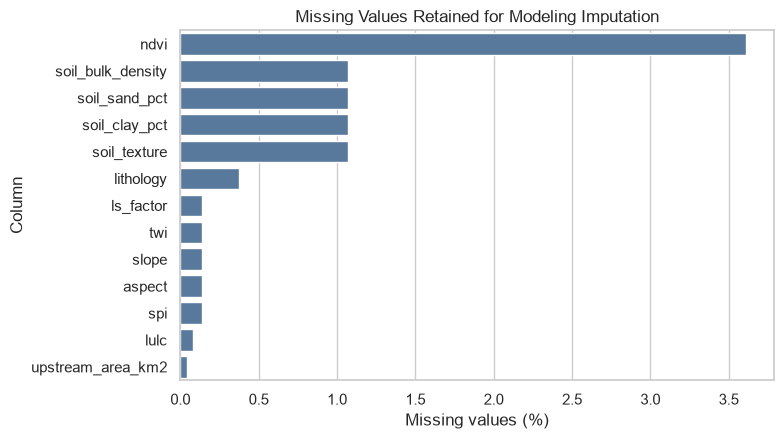

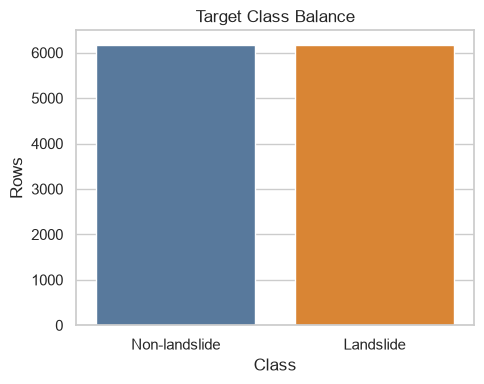

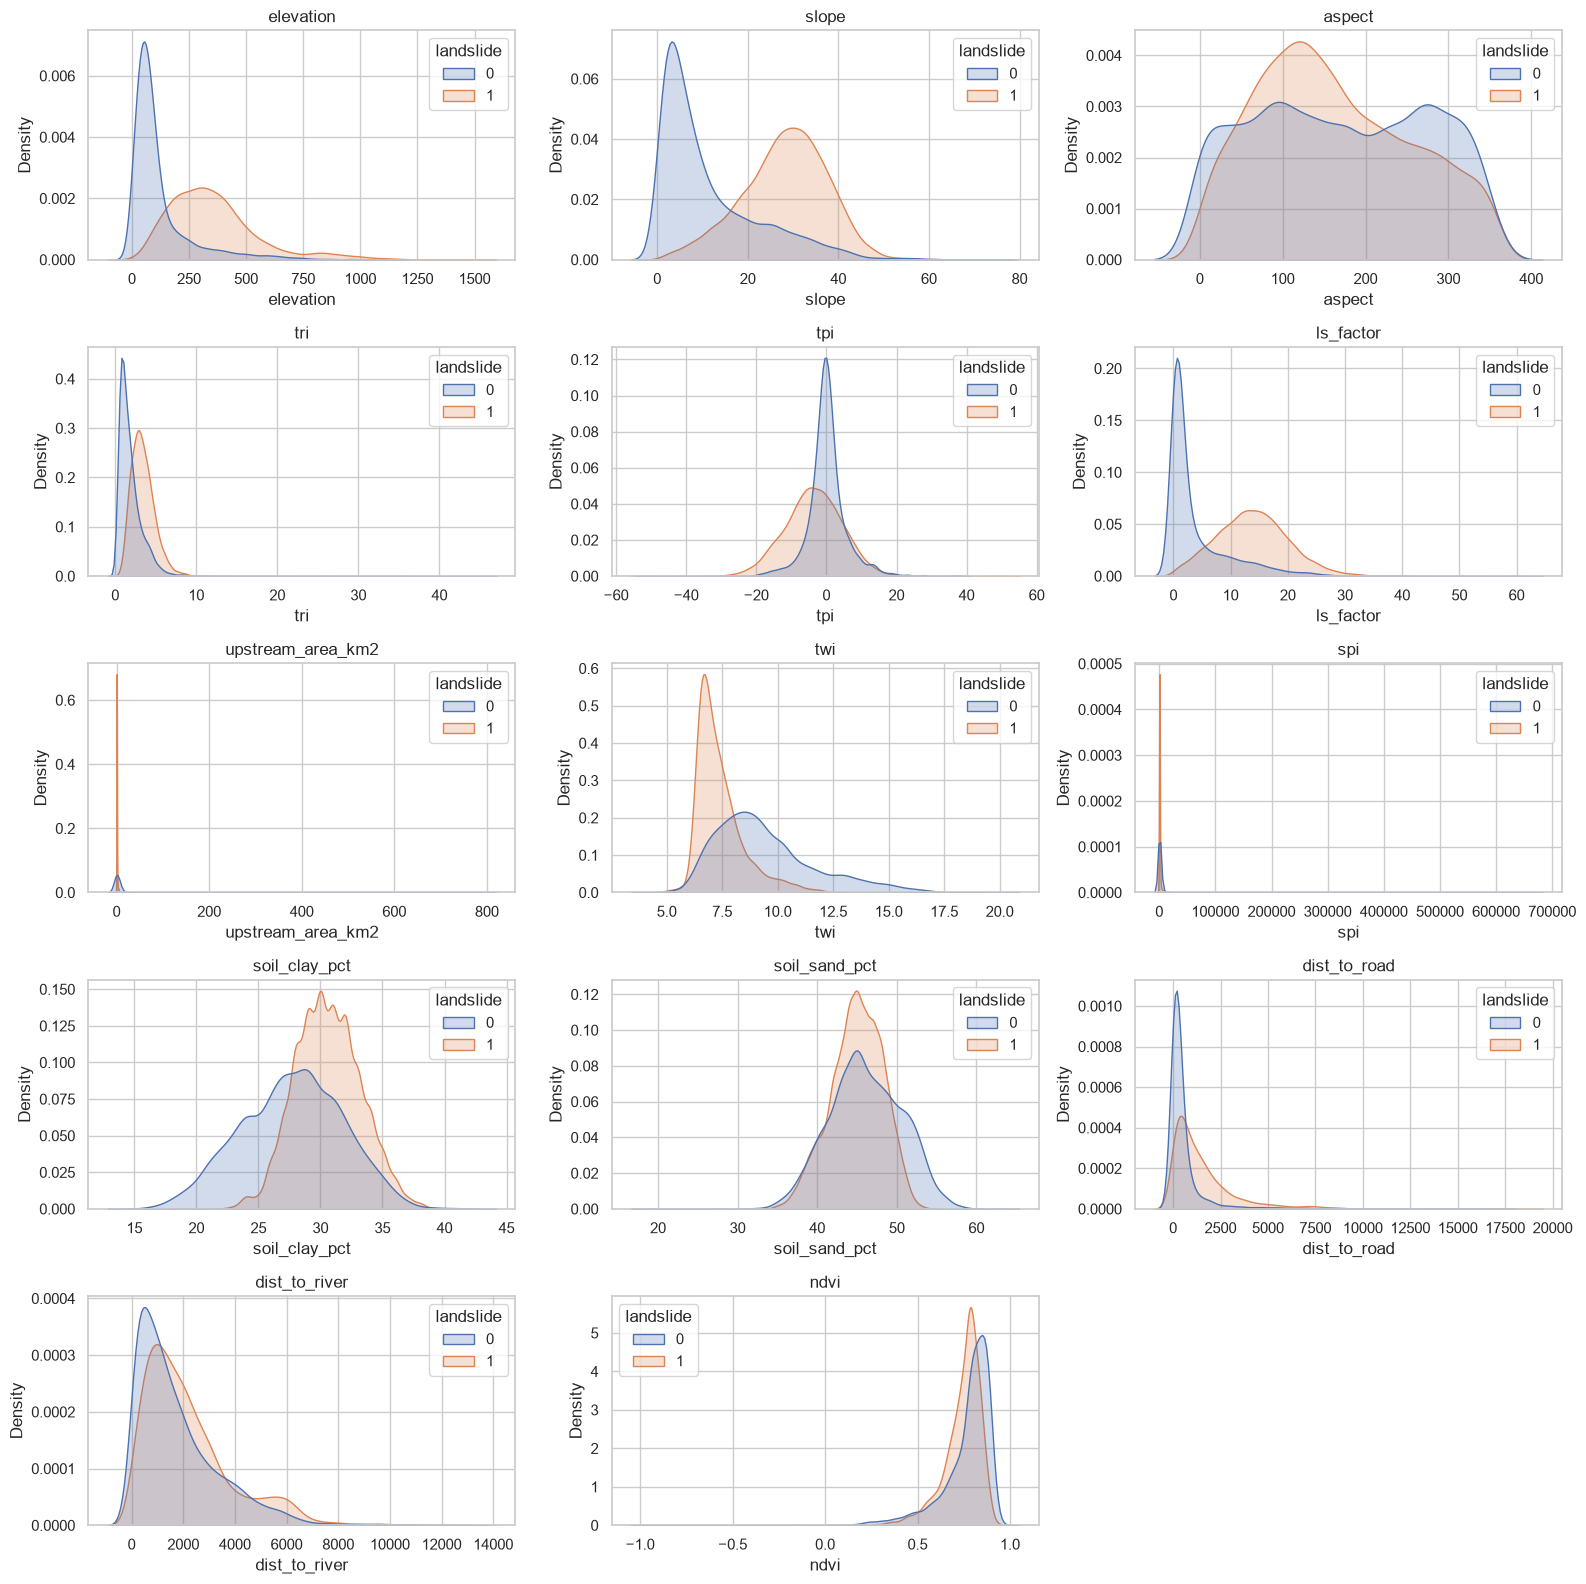

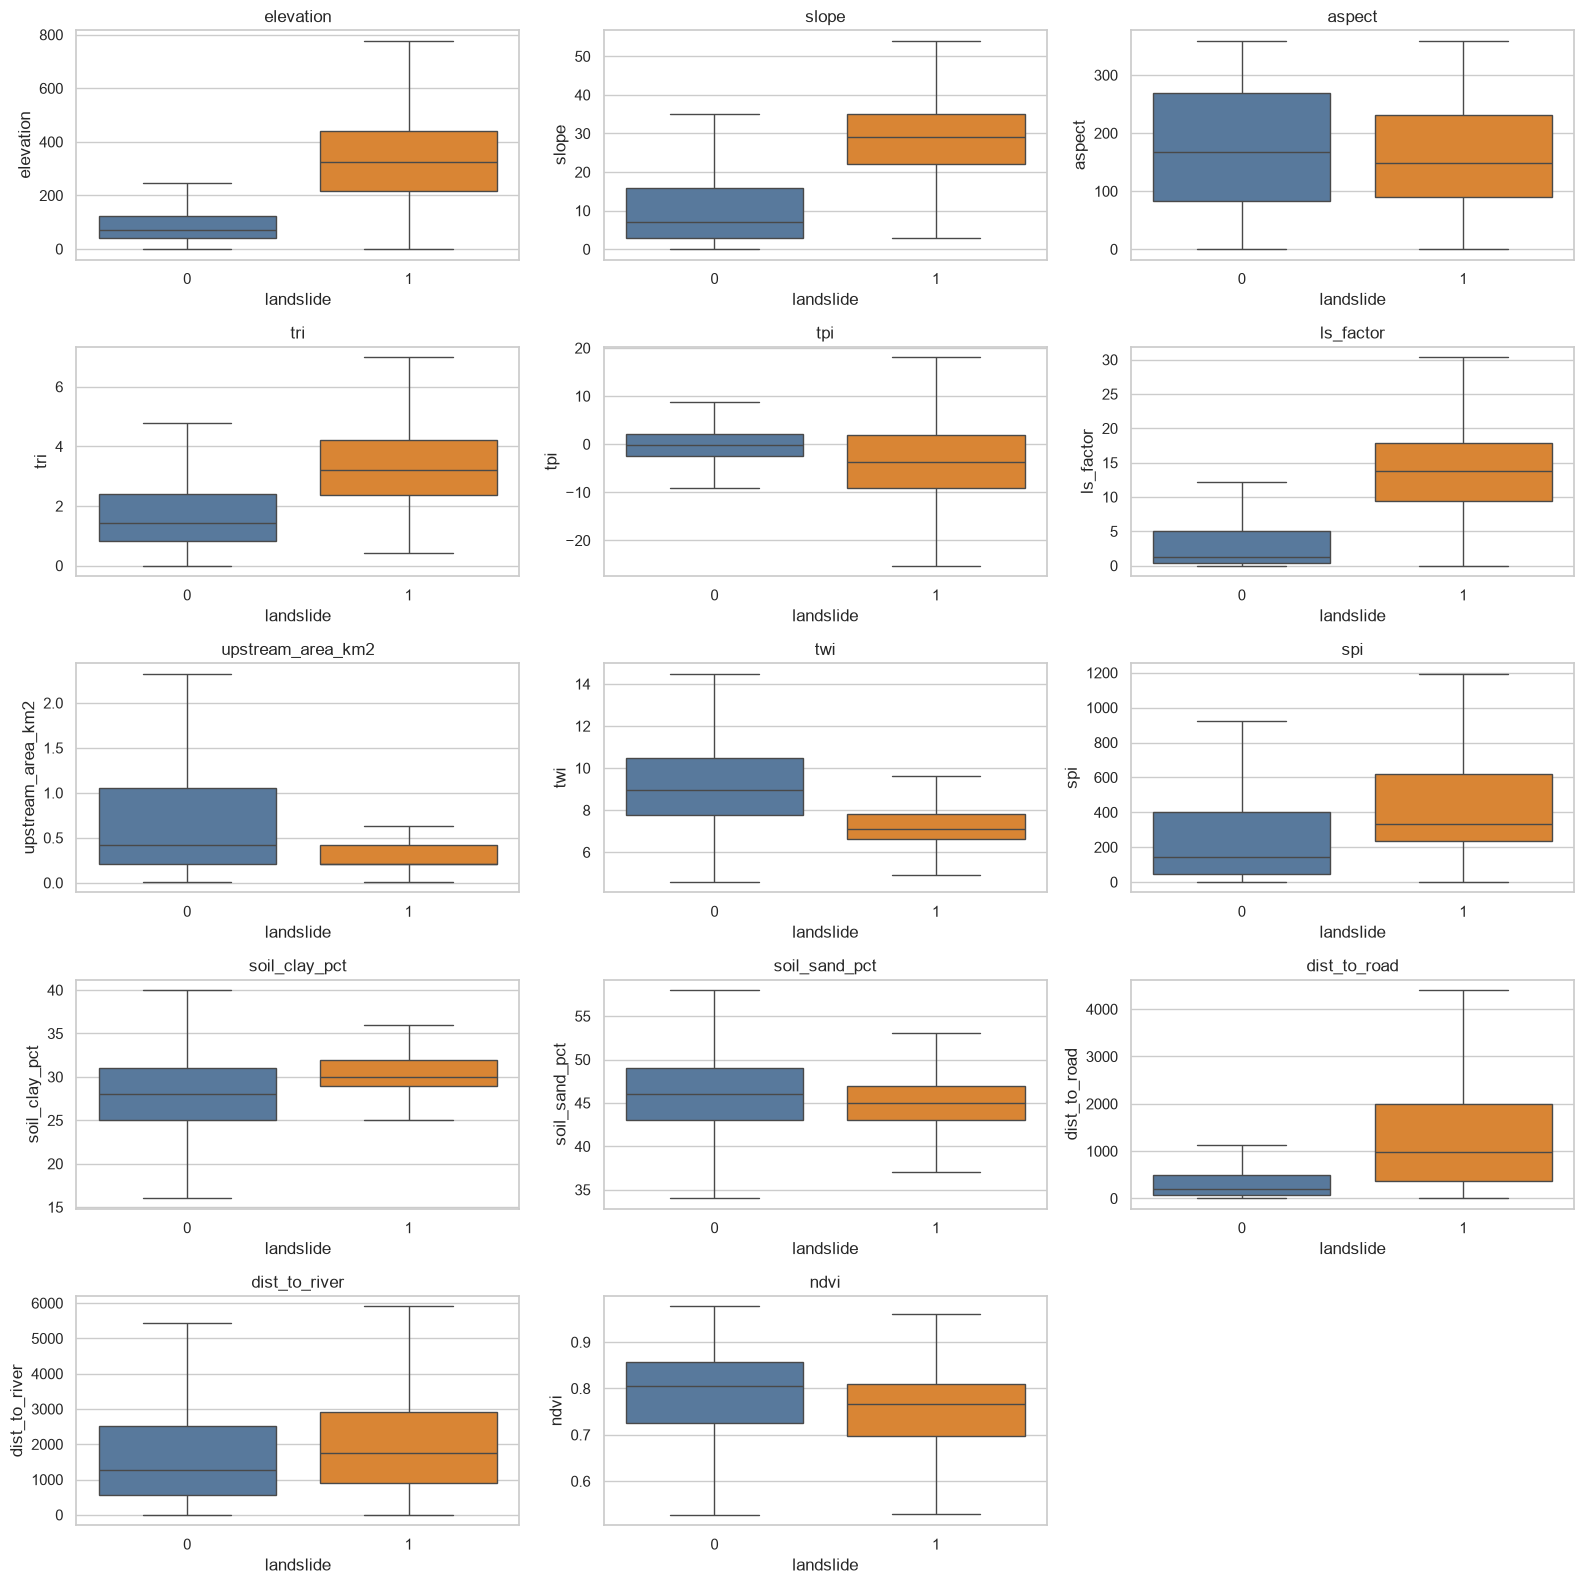

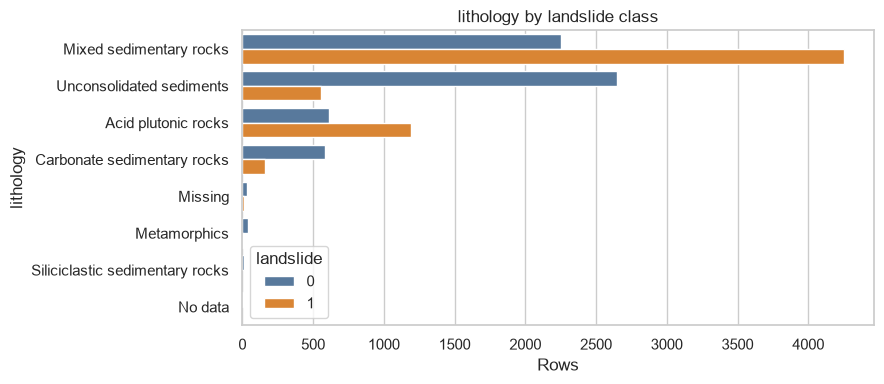

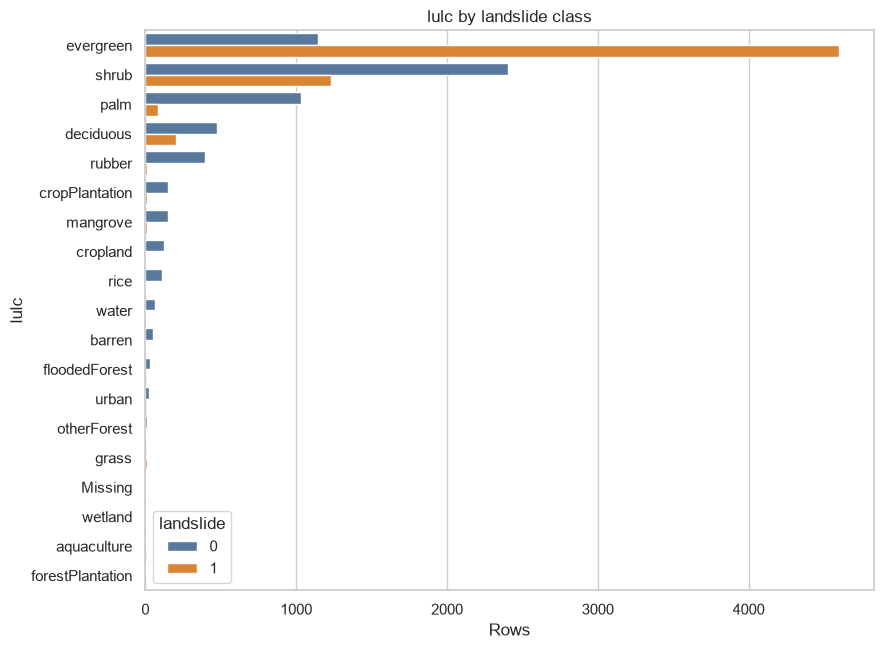

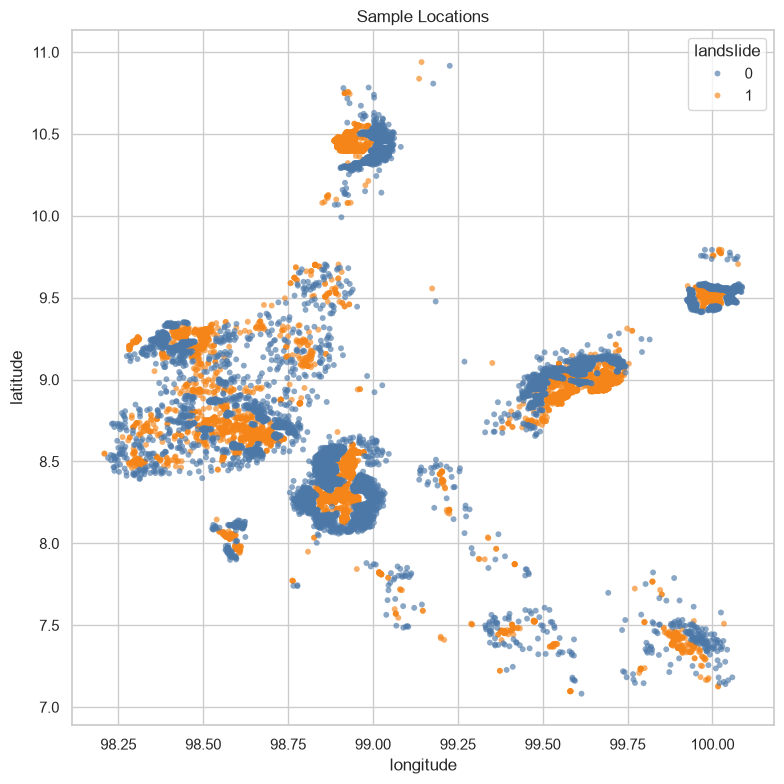

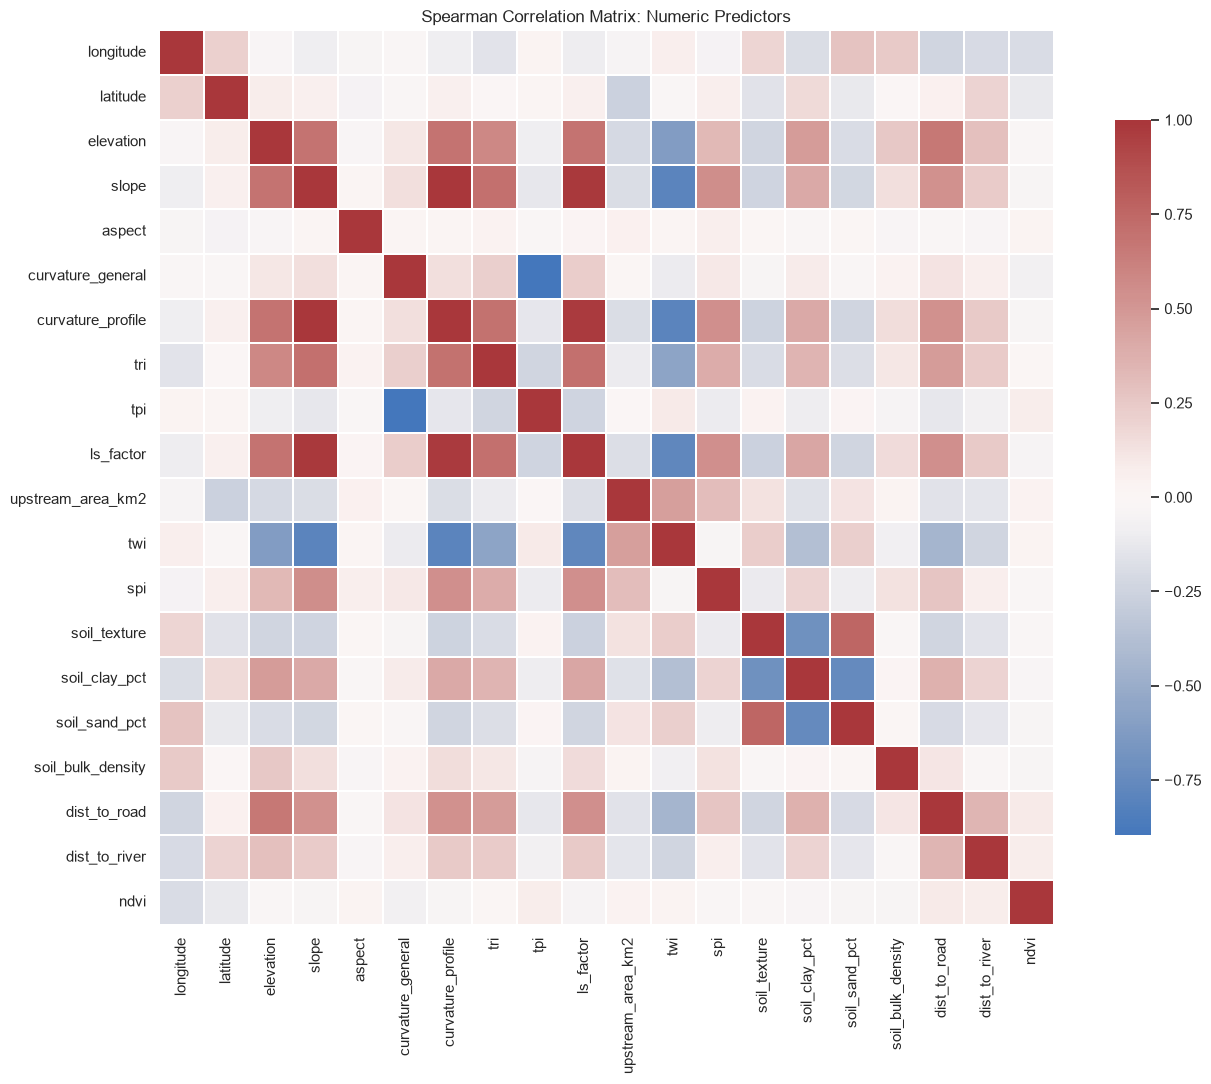

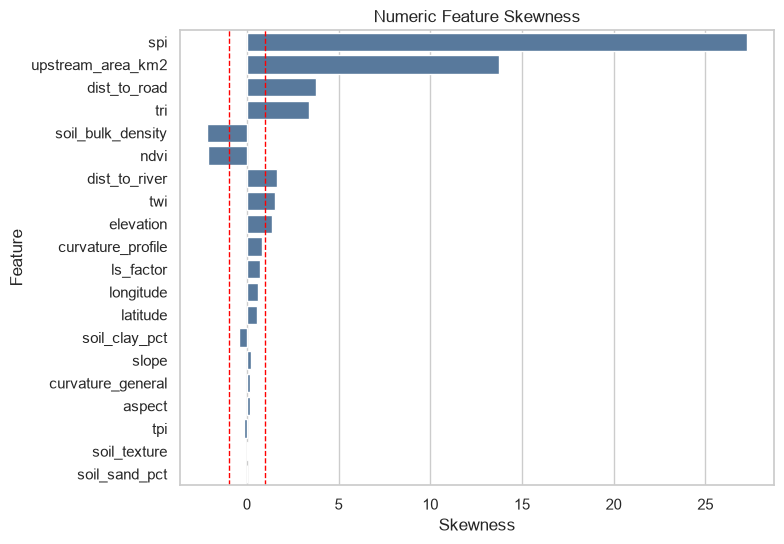

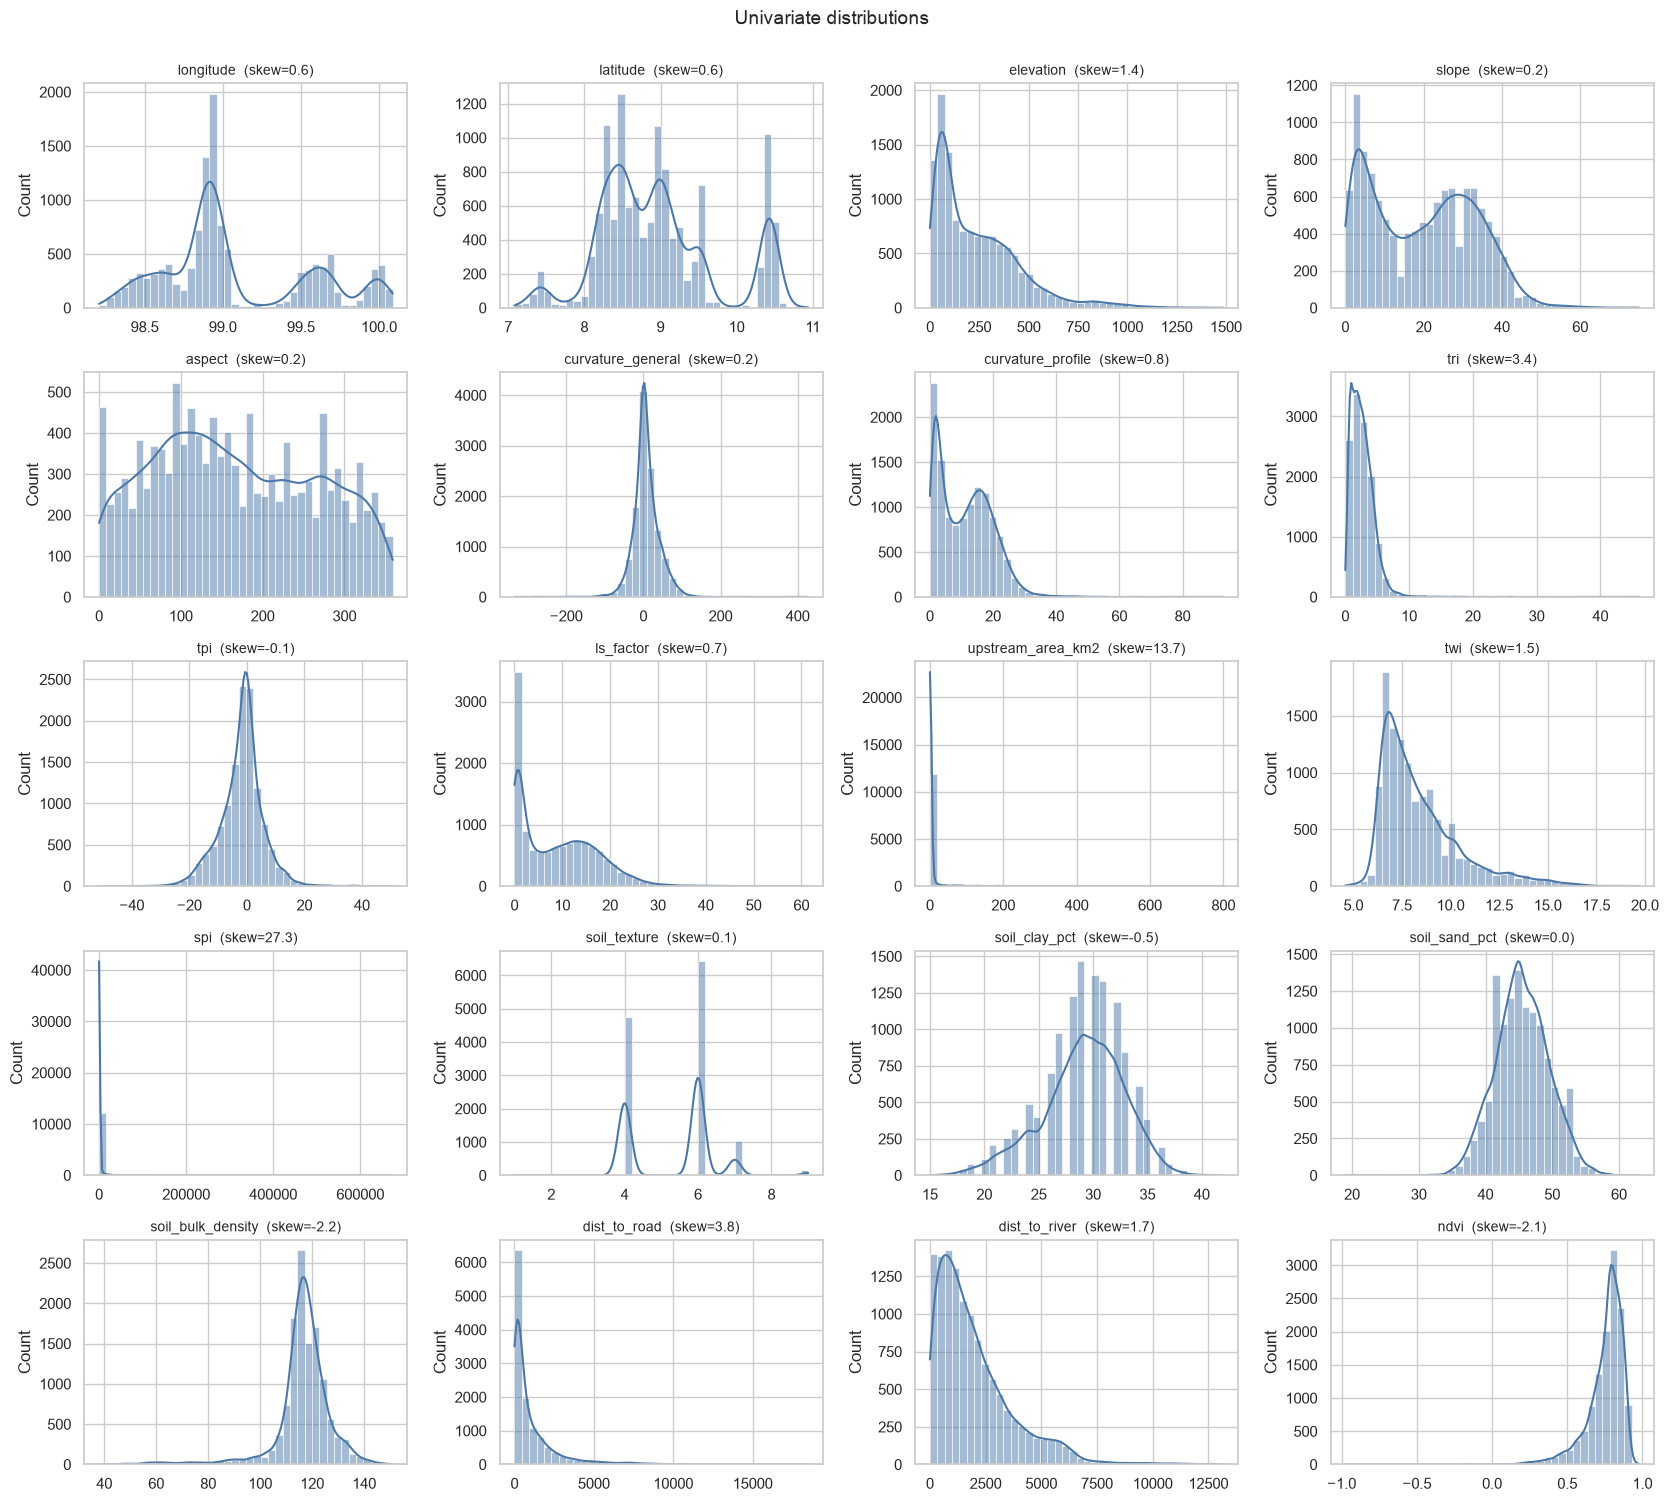

In [18]:
def grid(n, ncols=4, h=3):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis('off')
    return fig, axes

fig, axes = grid(len(num_cols))
for ax, col in zip(axes, num_cols):
    sns.histplot(eda[col], kde=True, bins=40, color='#4C78A8', ax=ax)
    ax.set_title(f'{col}  (skew={eda[col].skew():.1f})', fontsize=10)
    ax.set_xlabel('')
plt.suptitle('Univariate distributions', y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

### Univariate: boxplots (with outliers shown) for every numeric predictor

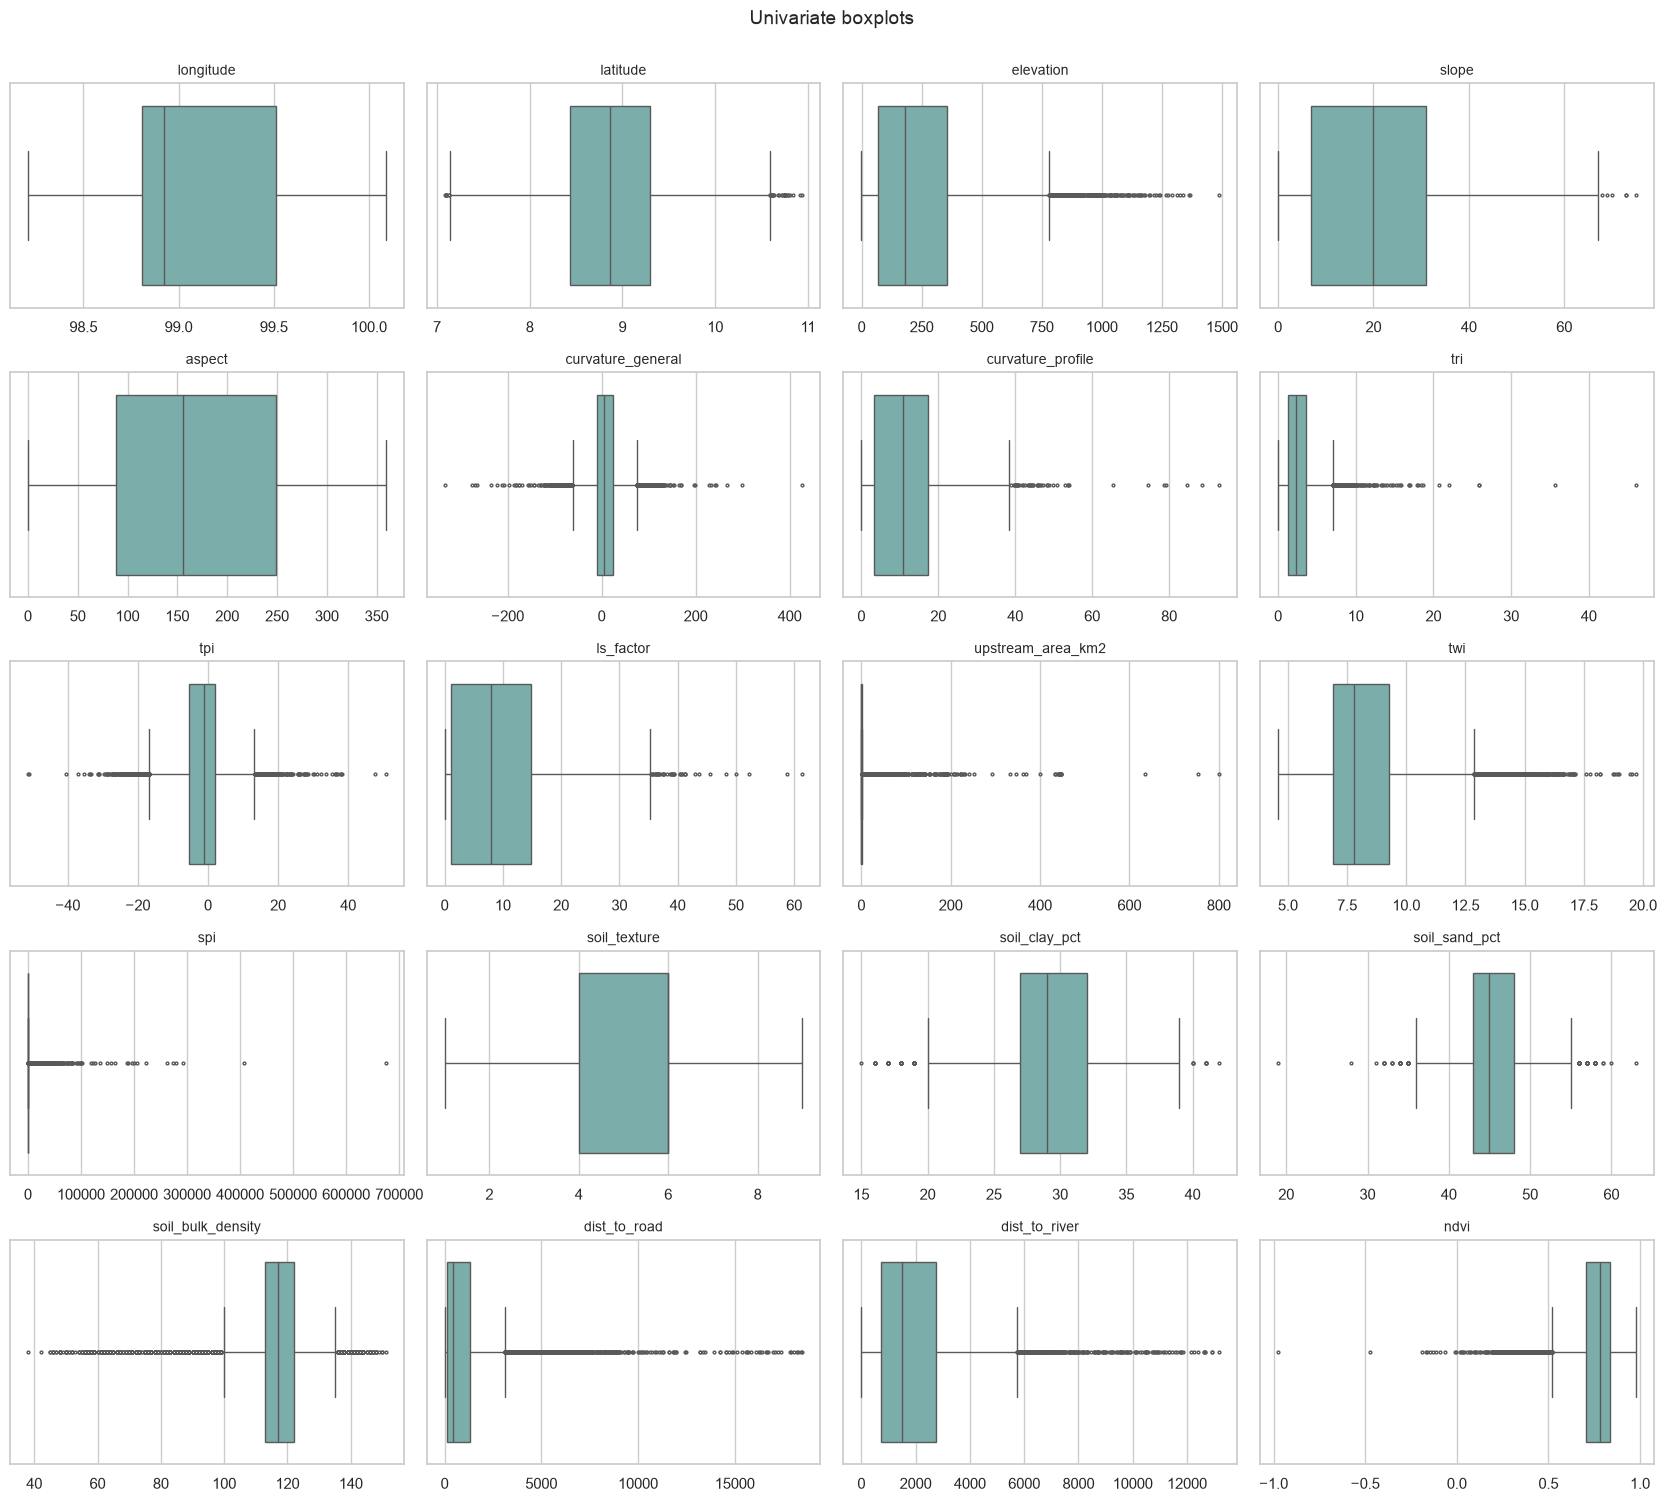

In [19]:
fig, axes = grid(len(num_cols))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=eda[col], color='#72B7B2', ax=ax, fliersize=2)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
plt.suptitle('Univariate boxplots', y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

### Univariate: skewed variables before vs after log1p

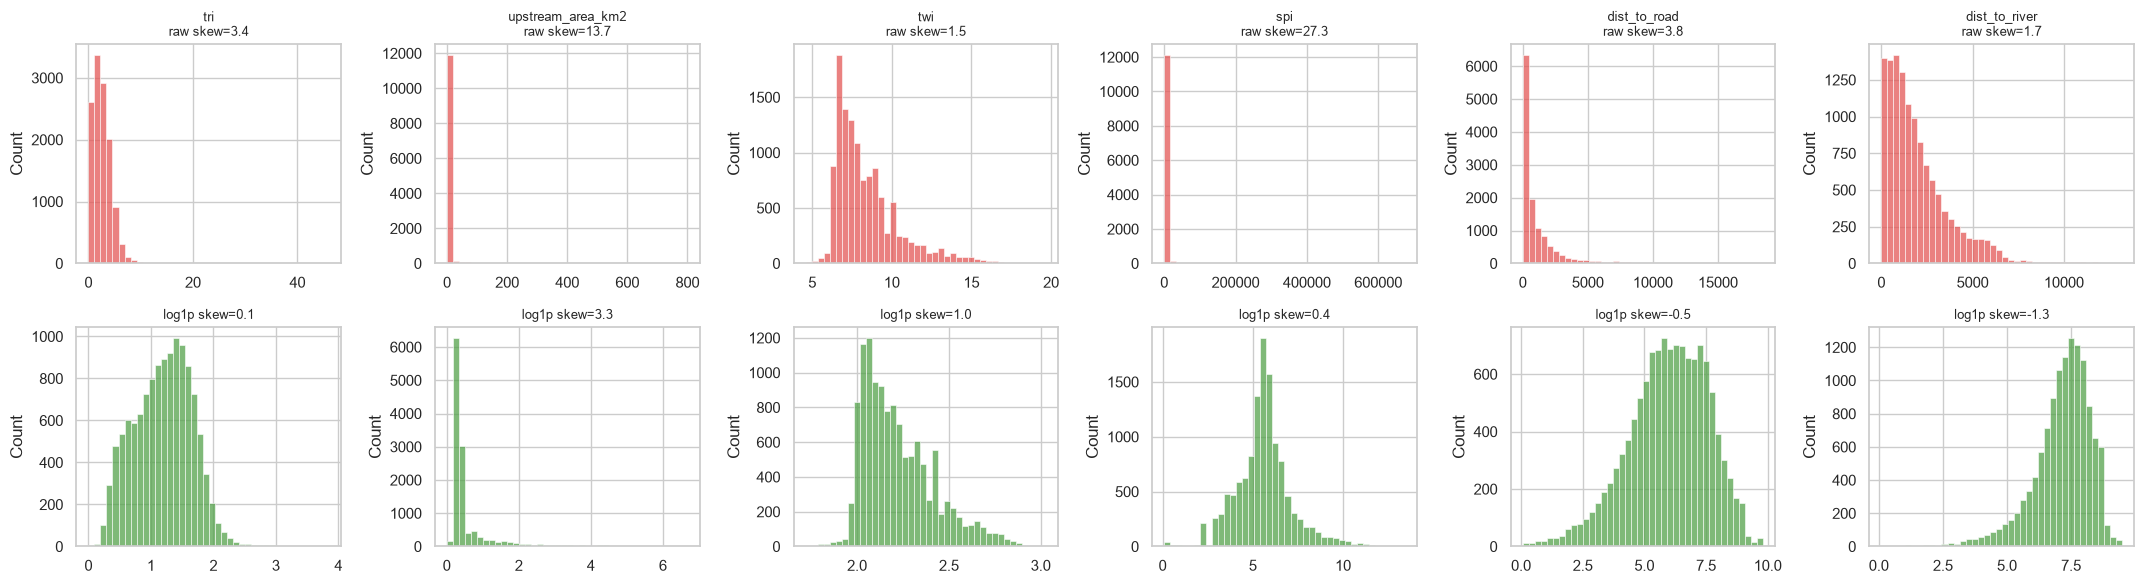

In [20]:
skewed = [c for c in num_cols if eda[c].skew() > 1 and eda[c].min() >= 0][:6]
fig, axes = plt.subplots(2, len(skewed), figsize=(3.6 * len(skewed), 6))
for j, col in enumerate(skewed):
    sns.histplot(eda[col], bins=40, color='#E45756', ax=axes[0, j]); axes[0, j].set_title(f'{col}\nraw skew={eda[col].skew():.1f}', fontsize=9)
    sns.histplot(np.log1p(eda[col]), bins=40, color='#54A24B', ax=axes[1, j]); axes[1, j].set_title(f'log1p skew={np.log1p(eda[col]).skew():.1f}', fontsize=9)
    axes[0, j].set_xlabel(''); axes[1, j].set_xlabel('')
plt.tight_layout()
plt.show()

### Univariate: categorical counts

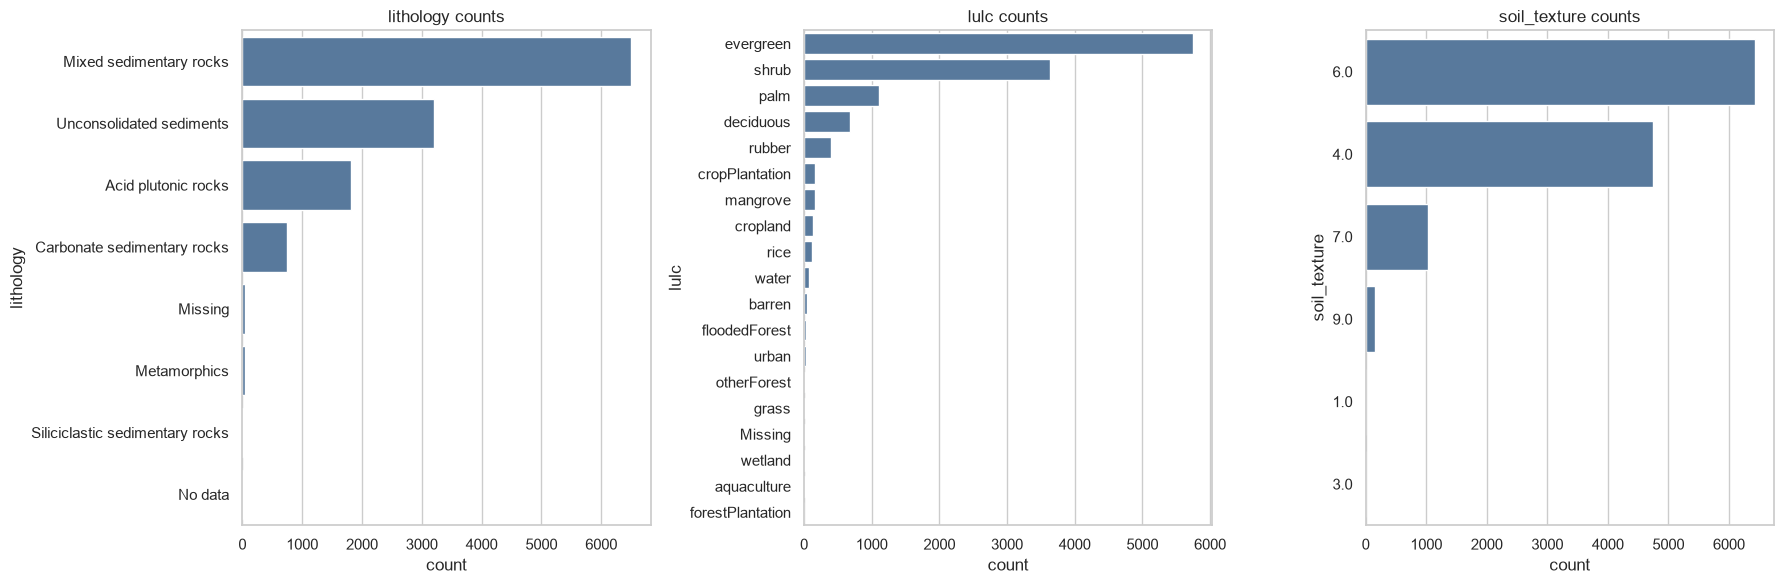

In [21]:
cat_plot_cols = ['lithology', 'lulc', 'soil_texture']
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, cat_plot_cols):
    order = eda[col].value_counts().index
    sns.countplot(data=eda, y=col, order=order, color='#4C78A8', ax=ax)
    ax.set_title(f'{col} counts')
plt.tight_layout()
plt.show()

### Missing-value map (each row of the heatmap is a sample; light cells are missing)

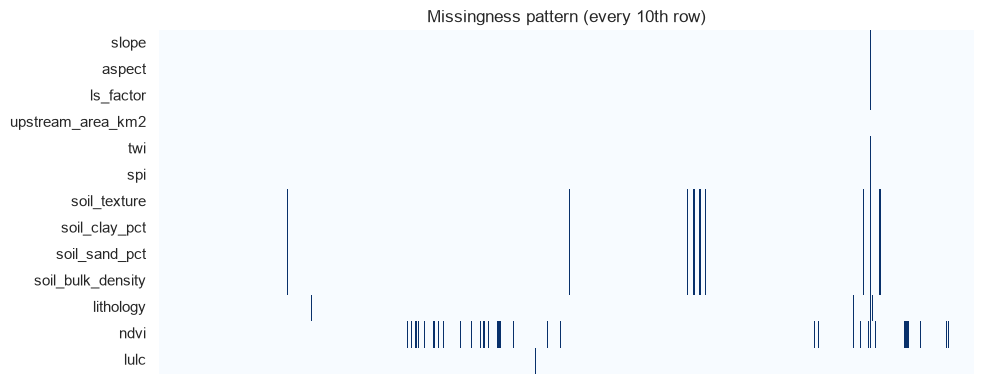

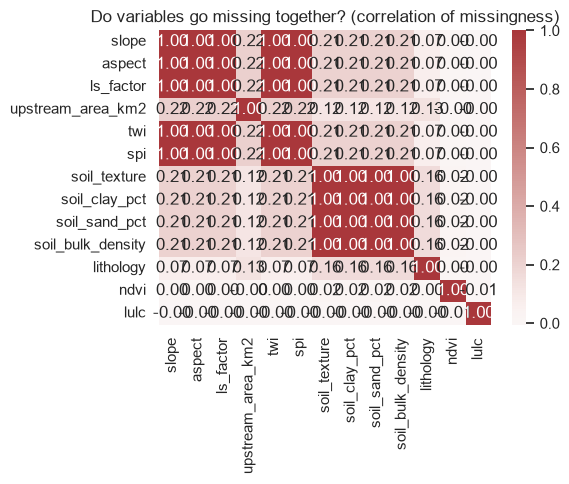

In [22]:
cols_missing = [c for c in df.columns if df[c].isna().any()]
plt.figure(figsize=(10, 4))
sns.heatmap(df[cols_missing].isna().T.iloc[:, ::10], cmap='Blues', cbar=False, yticklabels=True, xticklabels=False)
plt.title('Missingness pattern (every 10th row)')
plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 5))
sns.heatmap(df[cols_missing].isna().corr(), annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Do variables go missing together? (correlation of missingness)')
plt.tight_layout()
plt.show()

### Bivariate: numeric predictors by class (violin plots)

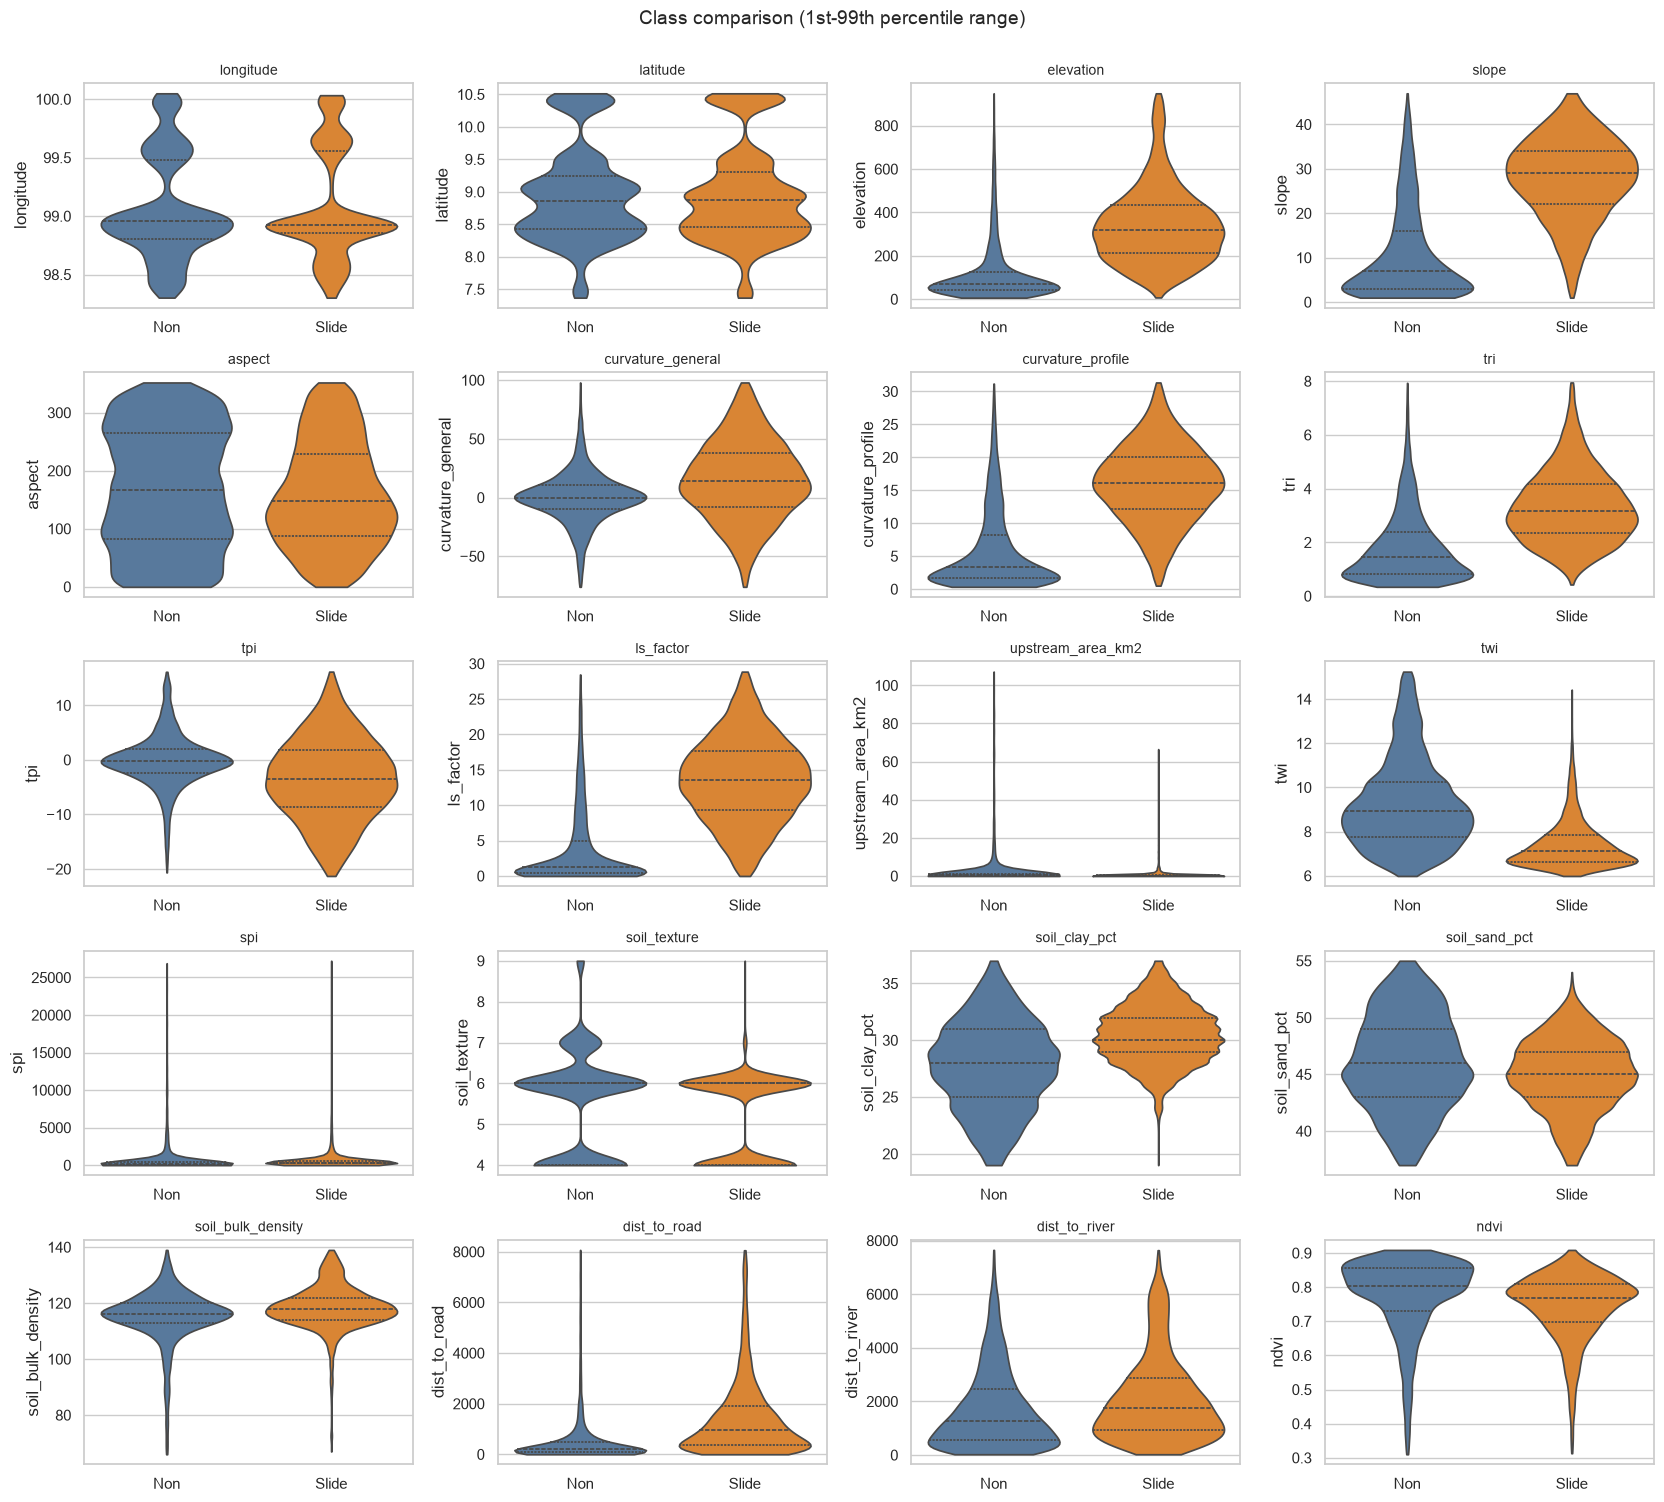

In [23]:
fig, axes = grid(len(num_cols))
for ax, col in zip(axes, num_cols):
    lo, hi = eda[col].quantile([0.01, 0.99])
    sns.violinplot(data=eda[(eda[col] >= lo) & (eda[col] <= hi)], x='landslide', y=col, palette=PAL_L, inner='quartile', ax=ax, cut=0)
    ax.set_title(col, fontsize=10); ax.set_xlabel(''); ax.set_xticklabels(['Non', 'Slide'])
plt.suptitle('Class comparison (1st-99th percentile range)', y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

### Bivariate: landslide rate by category (bar charts) and category x class counts

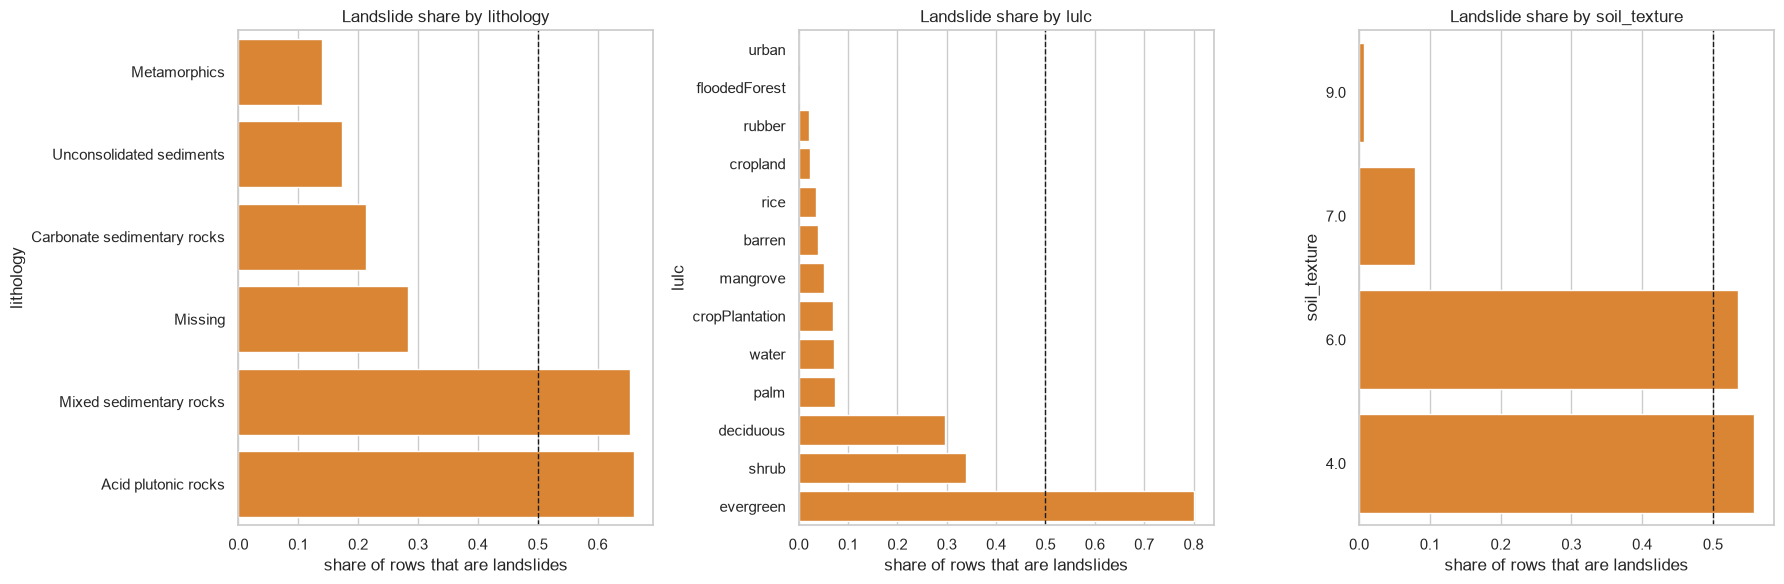

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, cat_plot_cols):
    rate = eda.groupby(col)['landslide'].agg(['mean', 'size']).sort_values('mean')
    rate = rate[rate['size'] >= 20]
    sns.barplot(x=rate['mean'], y=rate.index.astype(str), color='#F58518', ax=ax)
    ax.axvline(0.5, color='k', ls='--', lw=1)
    ax.set_title(f'Landslide share by {col}'); ax.set_xlabel('share of rows that are landslides')
plt.tight_layout()
plt.show()

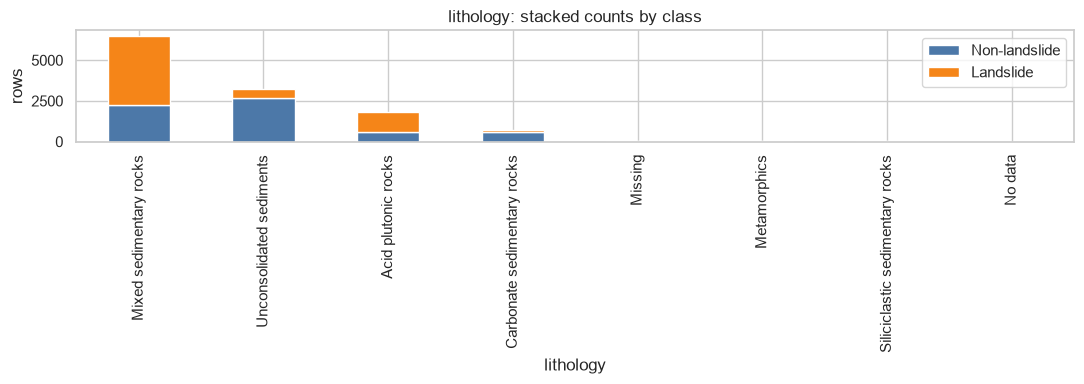

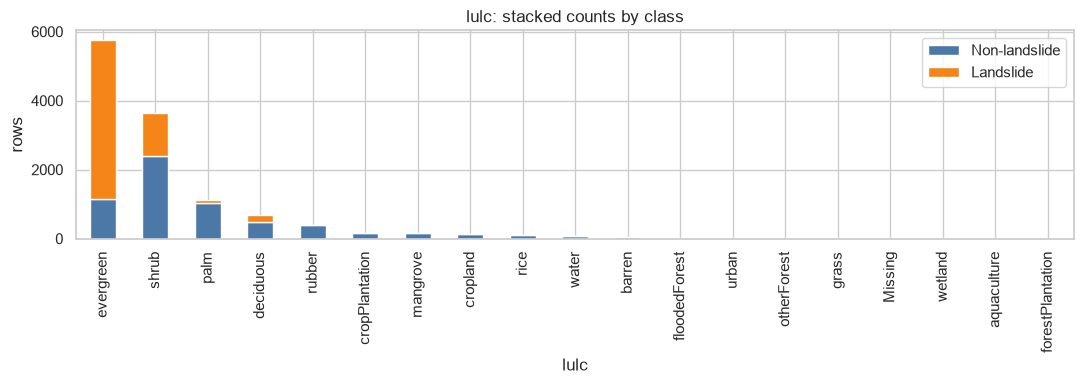

In [25]:
for col in ['lithology', 'lulc']:
    ct = pd.crosstab(eda[col], eda['landslide'])
    ct.loc[ct.sum(axis=1).sort_values(ascending=False).index].plot(kind='bar', stacked=True, color=[PAL[0], PAL[1]], figsize=(11, 4))
    plt.title(f'{col}: stacked counts by class'); plt.ylabel('rows'); plt.legend(['Non-landslide', 'Landslide'])
    plt.tight_layout(); plt.show()

### Bivariate: scatter plots of physically meaningful pairs, coloured by class

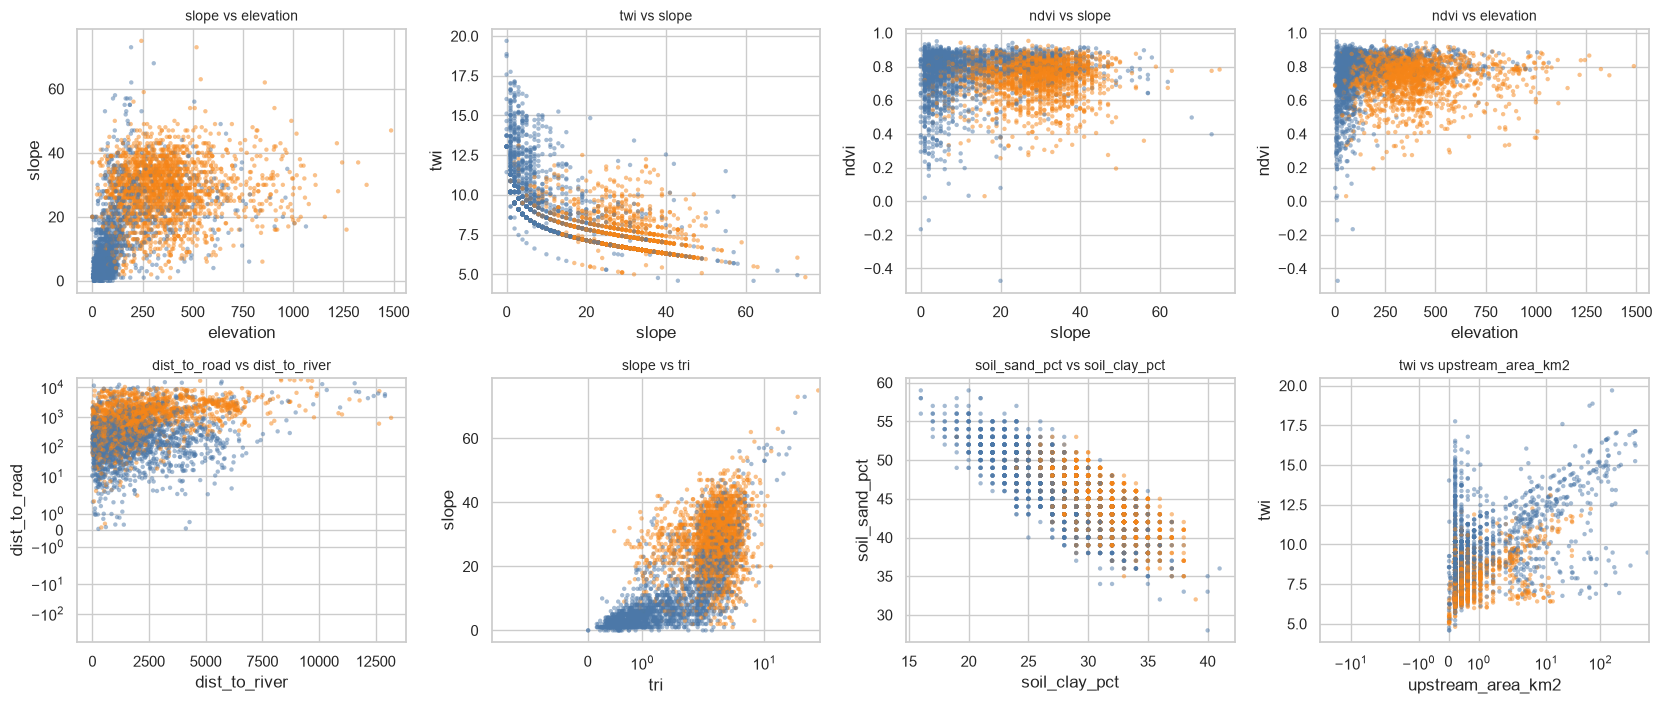

In [26]:
pairs = [('elevation', 'slope'), ('slope', 'twi'), ('slope', 'ndvi'), ('elevation', 'ndvi'),
         ('dist_to_river', 'dist_to_road'), ('tri', 'slope'), ('soil_clay_pct', 'soil_sand_pct'), ('upstream_area_km2', 'twi')]
pairs = [(a, b) for a, b in pairs if a in eda.columns and b in eda.columns]
fig, axes = grid(len(pairs), ncols=4, h=3.6)
samp = eda.sample(min(4000, len(eda)), random_state=RANDOM_STATE)
for ax, (a, b) in zip(axes, pairs):
    sns.scatterplot(data=samp, x=a, y=b, hue='landslide', palette=PAL, s=10, alpha=0.5, linewidth=0, ax=ax, legend=False)
    if samp[a].skew() > 2: ax.set_xscale('symlog')
    if samp[b].skew() > 2: ax.set_yscale('symlog')
    ax.set_title(f'{b} vs {a}', fontsize=10)
plt.tight_layout()
plt.show()

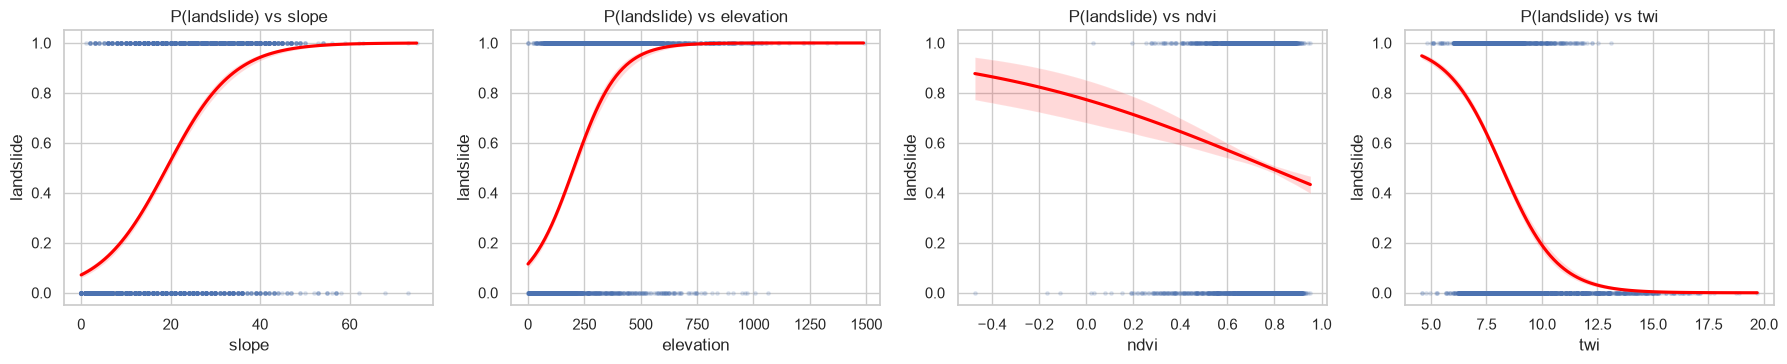

In [27]:
# Regression-style trend of landslide probability against key predictors (binned means with logistic fit).
key = [c for c in ['slope', 'elevation', 'ndvi', 'twi'] if c in eda.columns]
fig, axes = plt.subplots(1, len(key), figsize=(4.5 * len(key), 3.8))
for ax, col in zip(np.atleast_1d(axes), key):
    sns.regplot(data=samp, x=col, y='landslide', logistic=True, scatter_kws={'s': 6, 'alpha': 0.15}, line_kws={'color': 'red'}, ax=ax)
    ax.set_title(f'P(landslide) vs {col}')
plt.tight_layout()
plt.show()

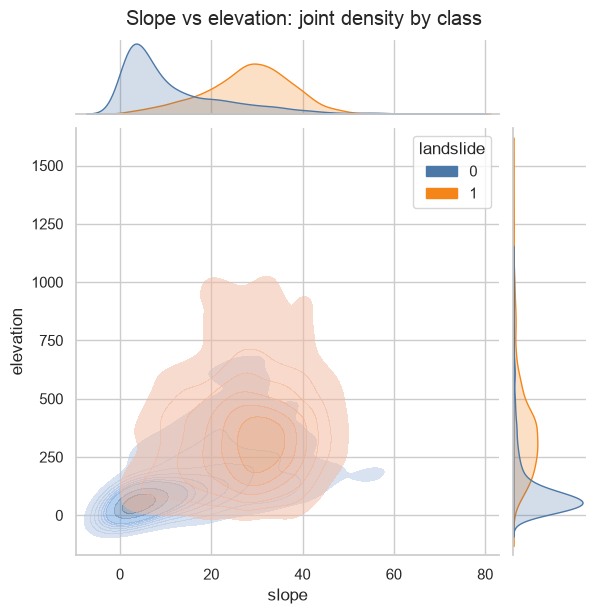

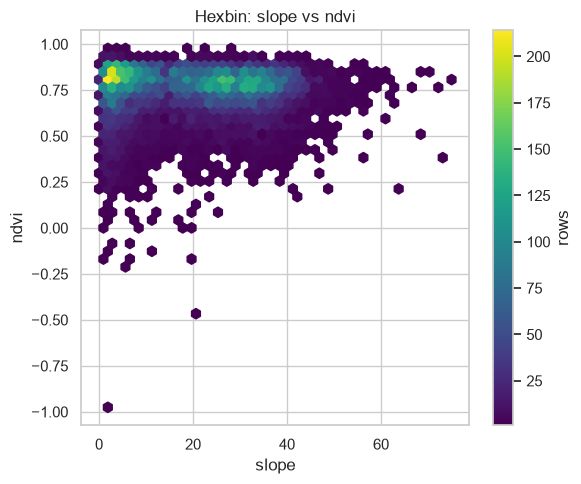

In [28]:
# Joint views: 2-D density and hexbin.
g = sns.jointplot(data=samp, x='slope', y='elevation', hue='landslide', palette=PAL, kind='kde', fill=True, alpha=0.5, height=6)
g.figure.suptitle('Slope vs elevation: joint density by class', y=1.02)
plt.show()
plt.figure(figsize=(6, 5))
plt.hexbin(eda['slope'], eda['ndvi'], gridsize=40, cmap='viridis', mincnt=1)
plt.colorbar(label='rows'); plt.xlabel('slope'); plt.ylabel('ndvi'); plt.title('Hexbin: slope vs ndvi')
plt.tight_layout(); plt.show()

### Multivariate: correlation heatmaps (Pearson and Spearman, annotated, lower triangle)

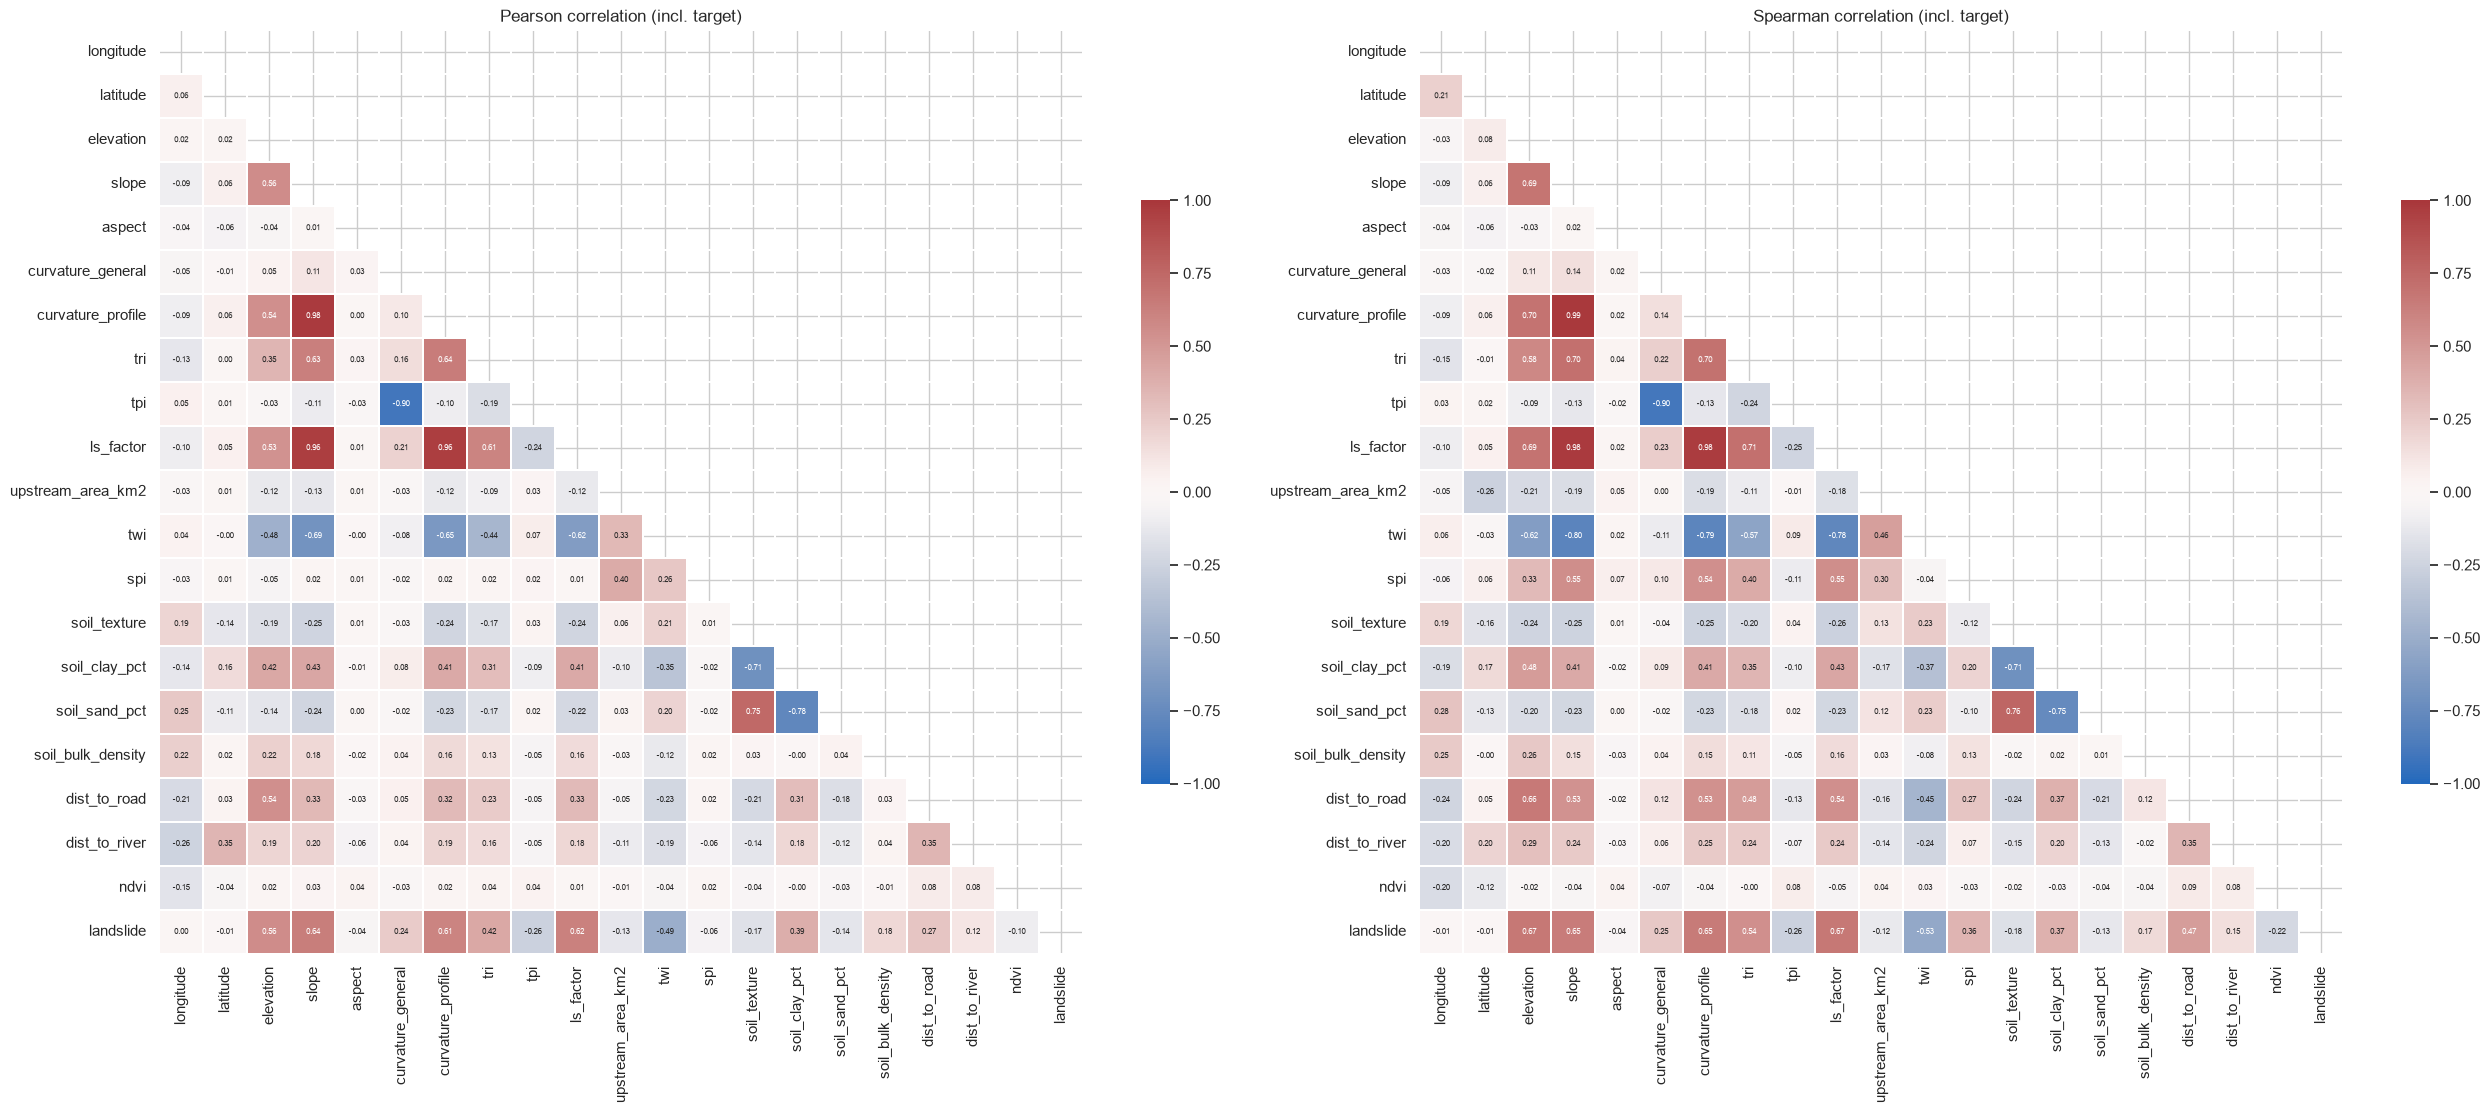

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(26, 11))
for ax, method in zip(axes, ['pearson', 'spearman']):
    c = eda[num_cols + ['landslide']].corr(method=method)
    mask = np.triu(np.ones_like(c, dtype=bool))
    sns.heatmap(c, mask=mask, cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 6},
                square=True, linewidths=0.3, cbar_kws={'shrink': 0.6}, ax=ax)
    ax.set_title(f'{method.title()} correlation (incl. target)')
plt.tight_layout()
plt.show()

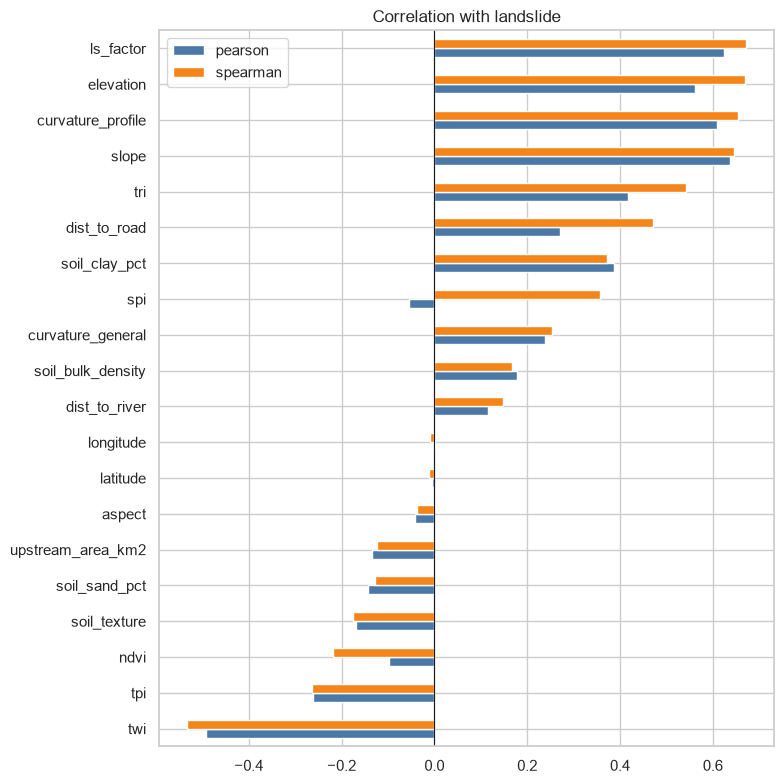

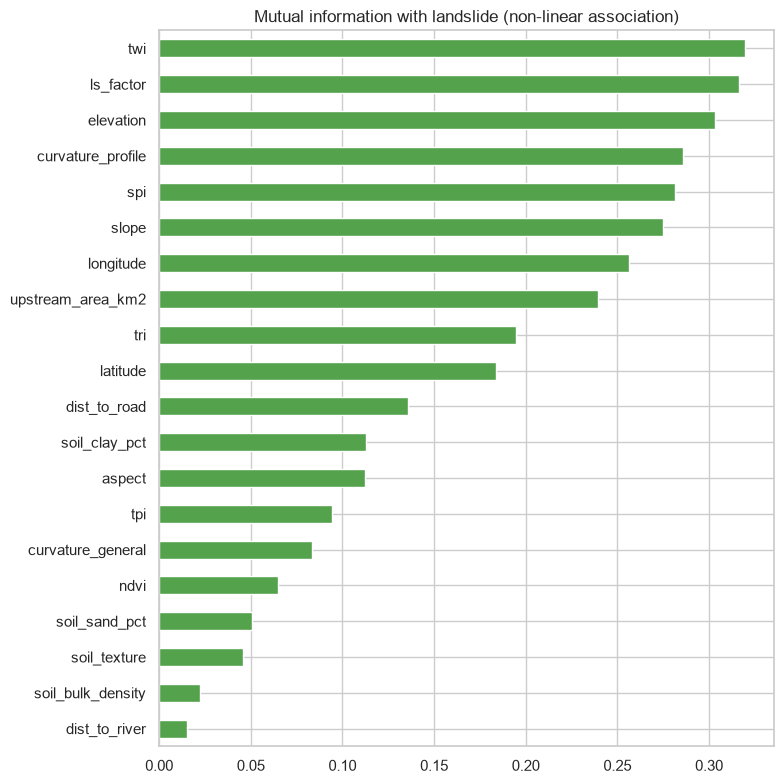

In [30]:
# Correlation of every predictor with the target, two ways.
tc = pd.DataFrame({
    'pearson': eda[num_cols].corrwith(eda['landslide'], method='pearson'),
    'spearman': eda[num_cols].corrwith(eda['landslide'], method='spearman'),
}).sort_values('spearman')
tc.plot(kind='barh', figsize=(8, 8), color=['#4C78A8', '#F58518'])
plt.axvline(0, color='k', lw=0.8); plt.title('Correlation with landslide'); plt.tight_layout(); plt.show()

# Mutual information captures non-linear association.
mi = mutual_info_classif(eda[num_cols], eda['landslide'], random_state=RANDOM_STATE)
pd.Series(mi, index=num_cols).sort_values().plot(kind='barh', figsize=(8, 8), color='#54A24B')
plt.title('Mutual information with landslide (non-linear association)'); plt.tight_layout(); plt.show()

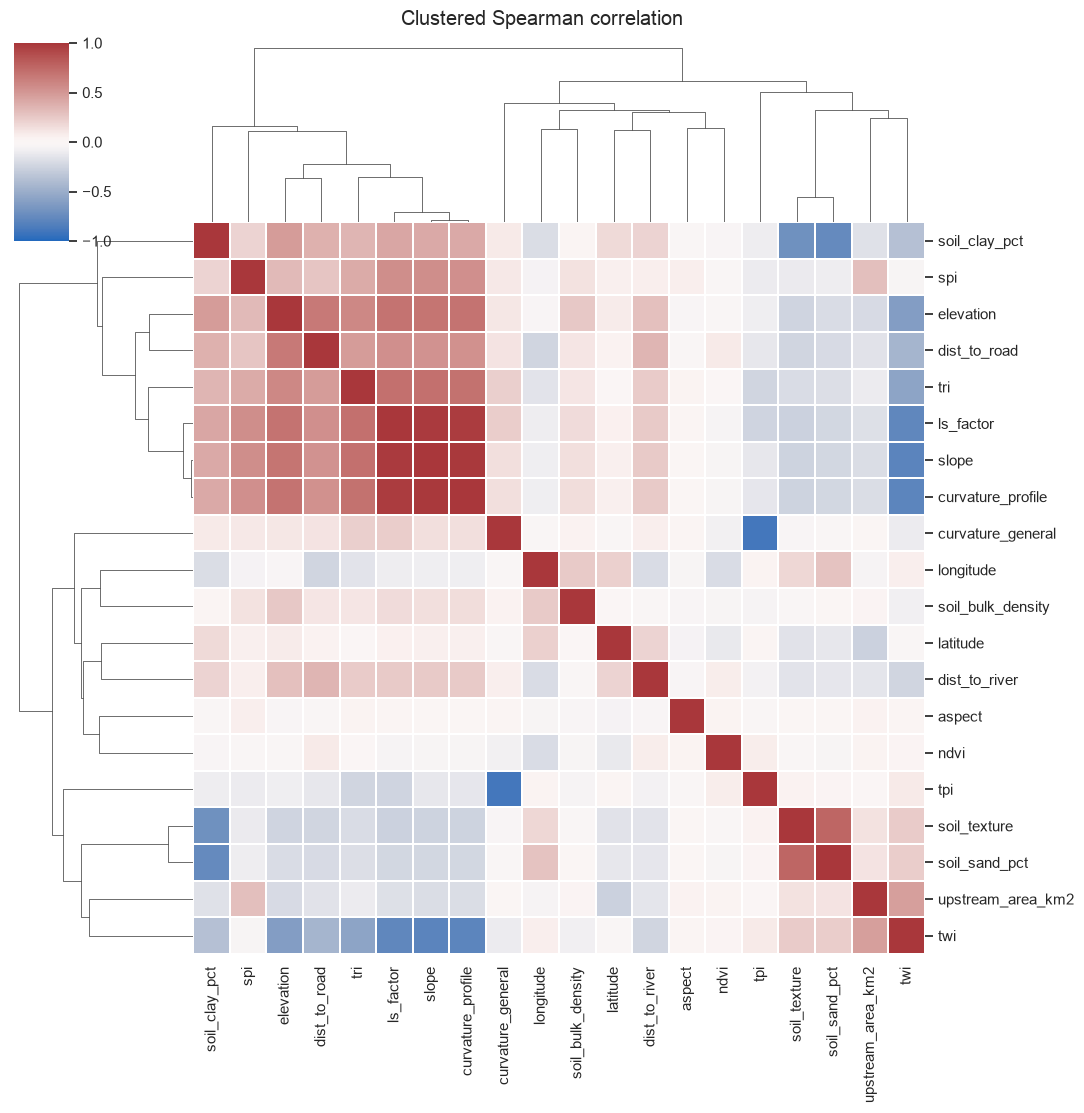

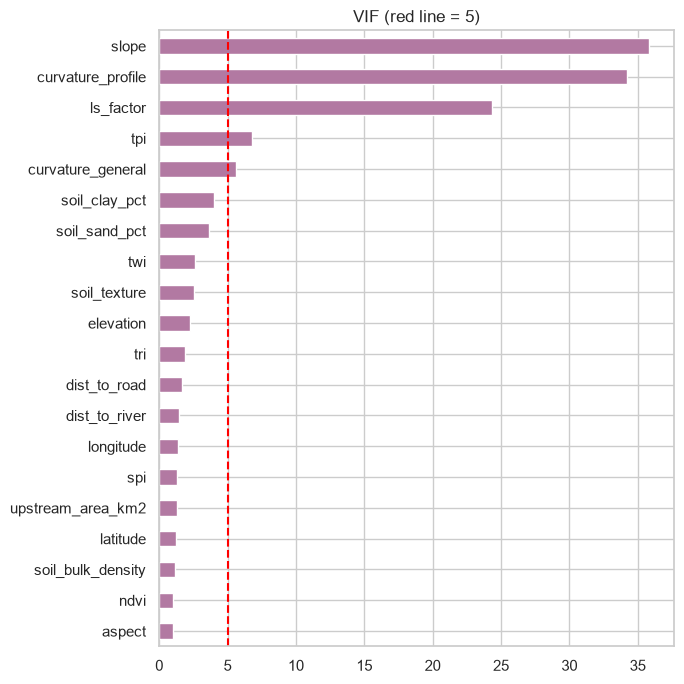

In [31]:
# Clustermap groups correlated predictors together (multicollinearity view).
cg = sns.clustermap(eda[num_cols].corr(method='spearman'), cmap='vlag', center=0, vmin=-1, vmax=1,
                    figsize=(11, 11), annot=False, linewidths=0.2)
cg.figure.suptitle('Clustered Spearman correlation', y=1.01)
plt.show()

# Variance inflation factors (VIF); values above ~5-10 signal problematic collinearity for linear models.
from sklearn.linear_model import LinearRegression
Z = (eda[num_cols] - eda[num_cols].mean()) / eda[num_cols].std()
vif = {c: 1 / (1 - LinearRegression().fit(Z.drop(columns=c), Z[c]).score(Z.drop(columns=c), Z[c])) for c in num_cols}
vif = pd.Series(vif).sort_values()
vif.plot(kind='barh', figsize=(7, 7), color='#B279A2'); plt.axvline(5, color='red', ls='--'); plt.title('VIF (red line = 5)'); plt.tight_layout(); plt.show()

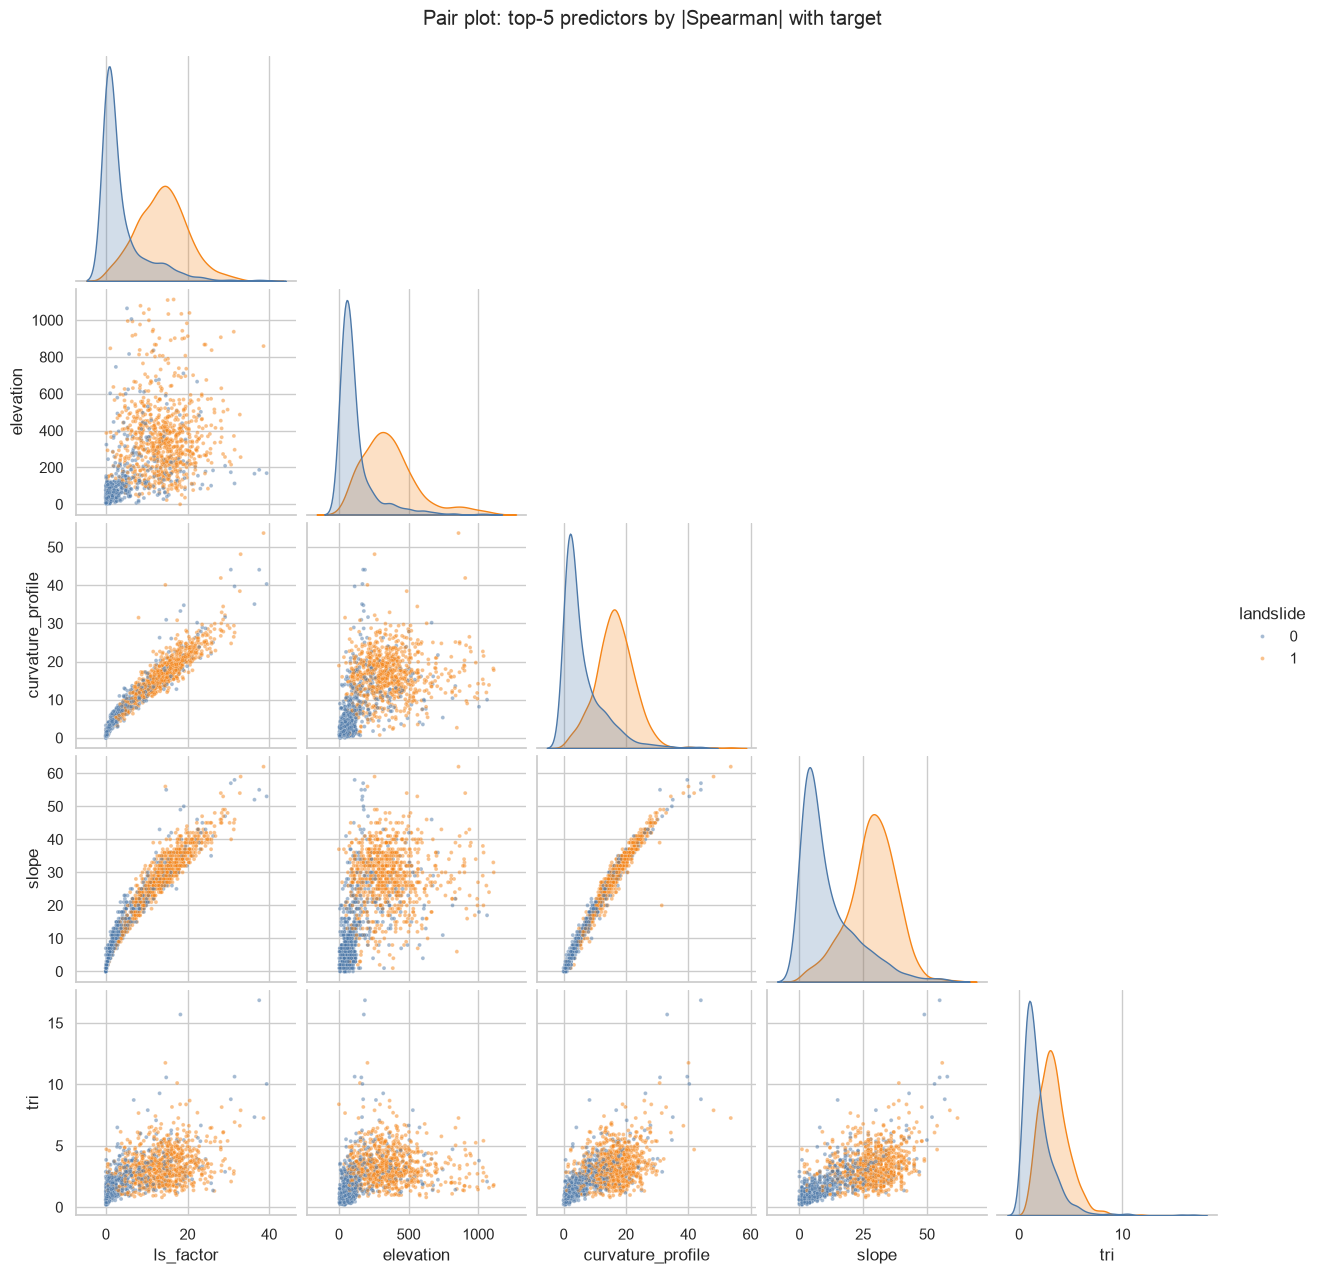

In [32]:
# Pair plot of the strongest predictors (sampled).
top_feats = tc['spearman'].abs().sort_values(ascending=False).head(5).index.tolist()
pp = sns.pairplot(samp.sample(1500, random_state=RANDOM_STATE), vars=top_feats, hue='landslide', palette=PAL,
                  corner=True, plot_kws={'s': 8, 'alpha': 0.5}, diag_kind='kde')
pp.figure.suptitle('Pair plot: top-5 predictors by |Spearman| with target', y=1.02)
plt.show()

### Spatial and temporal views

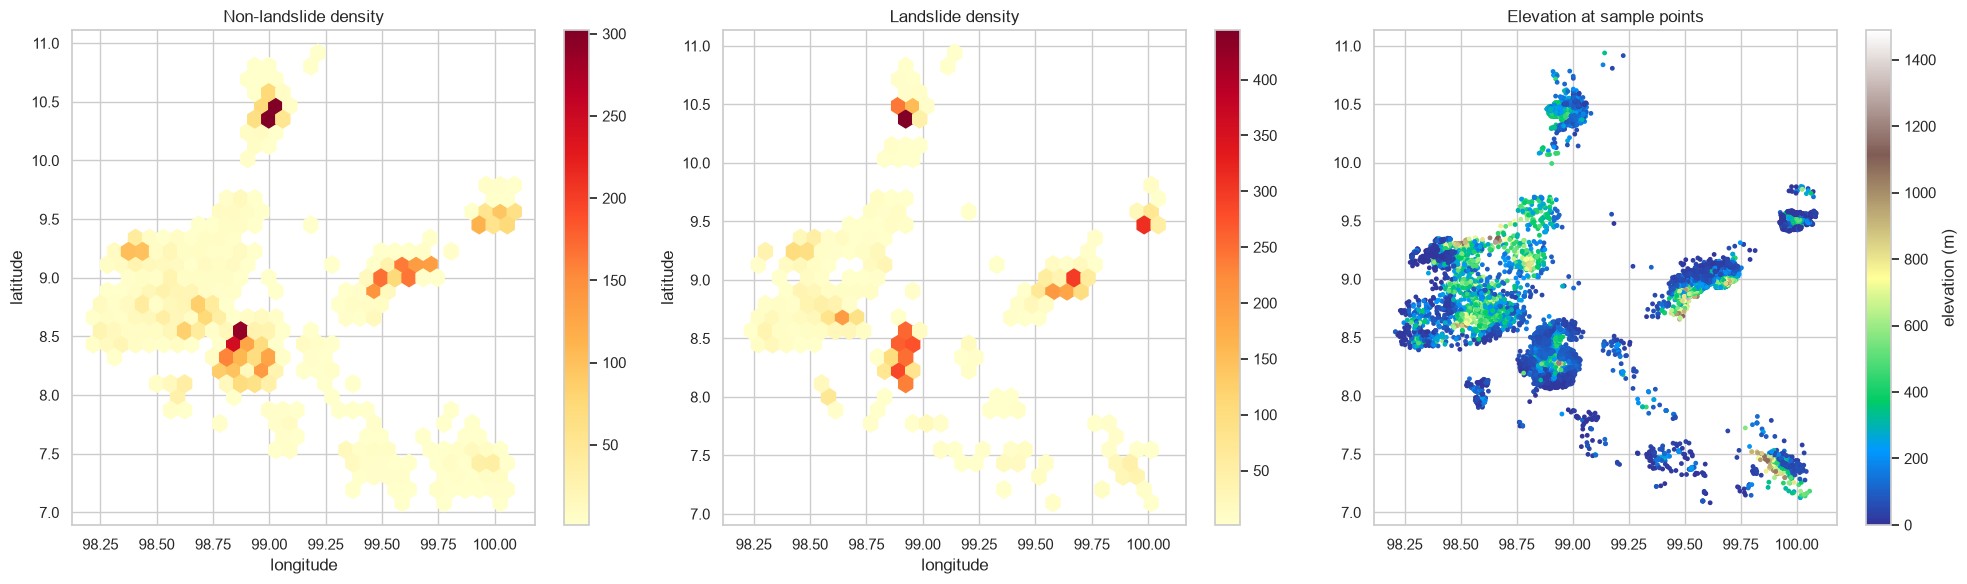

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (lbl, sub) in zip(axes[:2], eda.groupby('landslide')):
    hb = ax.hexbin(sub['longitude'], sub['latitude'], gridsize=30, cmap='YlOrRd', mincnt=1)
    ax.set_title(['Non-landslide', 'Landslide'][lbl] + ' density'); ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
    plt.colorbar(hb, ax=ax)
sc = axes[2].scatter(eda['longitude'], eda['latitude'], c=eda['elevation'], s=6, cmap='terrain')
plt.colorbar(sc, ax=axes[2], label='elevation (m)'); axes[2].set_title('Elevation at sample points')
plt.tight_layout(); plt.show()

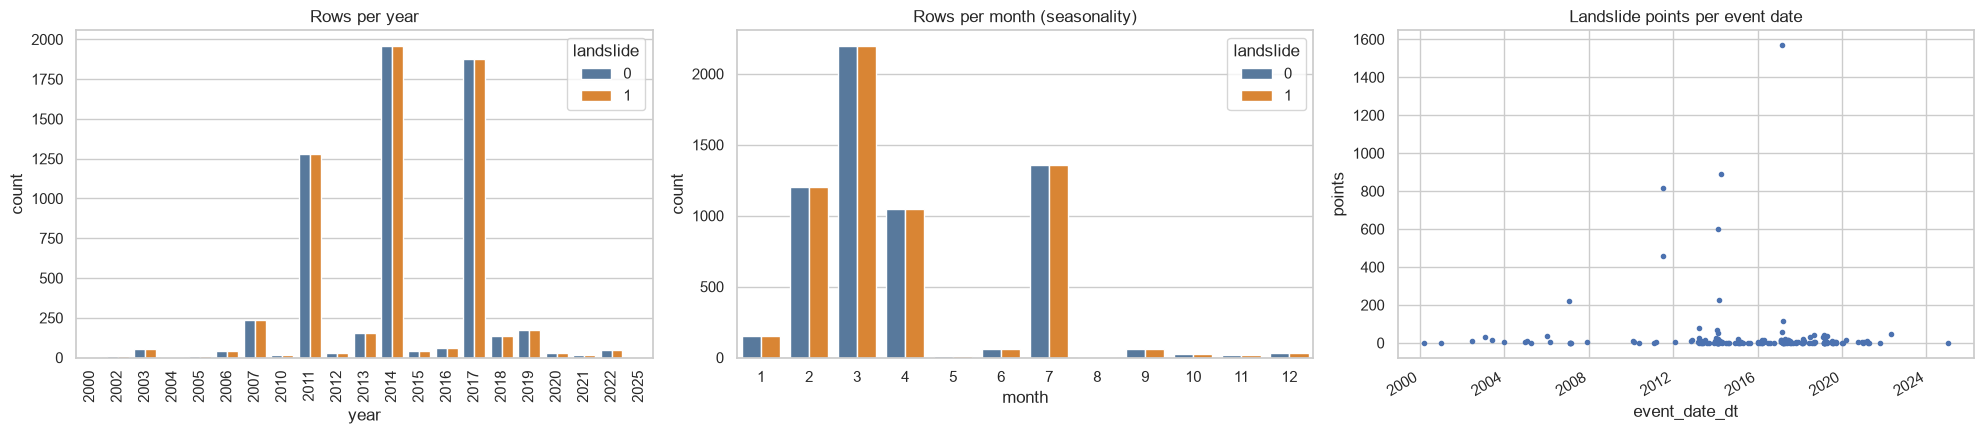

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
sns.countplot(data=eda, x='year', hue='landslide', palette=PAL_L, ax=axes[0]); axes[0].tick_params(axis='x', rotation=90); axes[0].set_title('Rows per year')
sns.countplot(data=eda, x='month', hue='landslide', palette=PAL_L, ax=axes[1]); axes[1].set_title('Rows per month (seasonality)')
ev = eda[eda['landslide'] == 1].groupby('event_date_dt').size()
ev.plot(ax=axes[2], marker='o', ls='', ms=3); axes[2].set_title('Landslide points per event date'); axes[2].set_ylabel('points')
plt.tight_layout(); plt.show()

### Outlier check (IQR method)

The IQR rule flags values outside Q1 - 1.5*IQR and Q3 + 1.5*IQR. Counts here are for inspection only (EDA copy). Several distance/flow variables have extreme values (e.g. `spi`, `curvature_general`). Outliers matter mostly for linear and distance-based models, so in the modeling pipeline the linear/SVM/KNN/Naive Bayes branch winsorises numeric columns with an IQR clipper fit on the **training data only**; tree models are left untouched.

In [35]:
q1, q3 = eda[num_cols].quantile(0.25), eda[num_cols].quantile(0.75)
iqr = q3 - q1
outlier_table = pd.DataFrame({
    'n_outliers': ((eda[num_cols] < q1 - 1.5 * iqr) | (eda[num_cols] > q3 + 1.5 * iqr)).sum(),
    'pct_outliers': (((eda[num_cols] < q1 - 1.5 * iqr) | (eda[num_cols] > q3 + 1.5 * iqr)).mean() * 100).round(1),
    'max': eda[num_cols].max(),
}).sort_values('pct_outliers', ascending=False)
outlier_table

,n_outliers,pct_outliers,max
upstream_area_km2,2038,16.5,800.583252
spi,1571,12.7,674469.046035
dist_to_road,1055,8.5,18493.982240
soil_bulk_density,894,7.2,151.000000
tpi,673,5.4,50.689655
ndvi,652,5.3,0.976924
curvature_general,619,5.0,427.000000
twi,621,5.0,19.696544
dist_to_river,525,4.2,13181.285361
elevation,358,2.9,1488.000000


## 5. Modeling Preprocessing Plan

`id`, `event_date`, longitude, and latitude are excluded from predictors. Coordinates define spatial groups and the validation buffer. Aspect is encoded as sine/cosine. Numeric values are median-imputed, with missingness indicators; categorical lithology, lulc, and soil texture are one-hot encoded. Linear and distance-based models also clip outliers, power-transform, and scale inside each training fold. Missingness differs by class in this dataset, so indicators may partly encode the sampling or raster coverage process; interpret their importance with care.

In [36]:
from scipy.spatial import cKDTree

COORD_COLS = ['longitude', 'latitude']
BLOCK_DEG = 0.5
BUFFER_KM = 5.0
N_OUTER, N_INNER = 5, 3
N_ITER = 8

target = 'landslide'
feature_cols = [c for c in df.columns if c not in ['id', 'event_date', target] + COORD_COLS]
cat_features = [c for c in ['lithology', 'lulc', 'soil_texture'] if c in feature_cols]
num_features = [c for c in feature_cols if c not in cat_features]
num_model_cols = [c for c in num_features if c != 'aspect'] + ['aspect_sin', 'aspect_cos']
X = df[feature_cols].copy()
y = df[target].astype(int)
groups = (np.floor(df['longitude'] / BLOCK_DEG).astype(int).astype(str) + '_' +
          np.floor(df['latitude'] / BLOCK_DEG).astype(int).astype(str))

# Local distance approximation in kilometres for a 5-km embargo.
latitude_radians = np.deg2rad(df['latitude'].mean())
xy_km = np.column_stack((df['longitude'] * 111.32 * np.cos(latitude_radians),
                         df['latitude'] * 111.32))

def buffered_train_indices(train, valid, coordinates=xy_km, buffer_km=BUFFER_KM):
    """Exclude training points closer than buffer_km to any validation point."""
    near = cKDTree(coordinates[valid]).query(coordinates[train], k=1)[0] < buffer_km
    kept = np.asarray(train)[~near]
    if len(kept) == 0 or len(np.unique(y.iloc[kept])) != 2:
        raise ValueError('Spatial buffer leaves too few training samples; revise BLOCK_DEG or BUFFER_KM.')
    return kept

print('Features:', len(feature_cols), '| categorical:', cat_features)
print('Spatial blocks:', groups.nunique(), '| median rows per block:', int(groups.value_counts().median()))

Features: 20 | categorical: ['lithology', 'lulc', 'soil_texture']
Spatial blocks: 27 | median rows per block: 144


### Spatially separated hold-out

Whole 0.5-degree blocks form groups. Training samples within 5 km of held-out samples are embargoed. The embargo removes points from **training folds only**, never from the CSV or held-out scoring set. It reduces immediate boundary leakage, although regional similarity and inventory clustering may remain. Among five folds generated with a fixed seed, choose the hold-out whose class share is closest to the full balanced sample and whose size is closest to 20%. This uses labels only, before fitting any model. Report class and block counts because the sample is spatially uneven.

In [37]:
outer_cv = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE)
# Choose a representative hold-out using only class counts and fold size.
# No predictors, probabilities, or test performance enter this decision.
holdout_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidate_splits = []
for fold_number, (raw_train, candidate_test) in enumerate(holdout_cv.split(X, y, groups)):
    candidate_train = buffered_train_indices(raw_train, candidate_test)
    balance_error = abs(y.iloc[candidate_train].mean() - y.mean()) + abs(y.iloc[candidate_test].mean() - y.mean())
    size_error = abs(len(candidate_test) / len(y) - 0.20)
    candidate_splits.append((balance_error + size_error, fold_number, raw_train, candidate_train, candidate_test))
_, holdout_fold, raw_train_idx, train_idx, test_idx = min(candidate_splits, key=lambda item: (item[0], item[1]))
print('Selected spatial hold-out fold:', holdout_fold)

X_train, y_train, g_train = X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx]
X_test, y_test, g_test = X.iloc[test_idx], y.iloc[test_idx], groups.iloc[test_idx]
assert not set(g_train) & set(g_test)
print('Train:', X_train.shape, y_train.value_counts().to_dict(), '| blocks:', g_train.nunique())
print('Test:', X_test.shape, y_test.value_counts().to_dict(), '| blocks:', g_test.nunique())
print('Embargoed from training:', len(raw_train_idx) - len(train_idx))

Selected spatial hold-out fold: 3
Train: (8280, 20) {1: 4284, 0: 3996} | blocks: 24
Test: (2628, 20) {0: 1505, 1: 1123} | blocks: 3
Embargoed from training: 1452


## 6. Pipelines and Search Spaces

The point sample is balanced by design. `class_weight='balanced'` applies where the estimator supports it; KNN and Gaussian Naive Bayes use learned class proportions. Precision, F1, PR-AUC, Brier scores, and isotonic calibration describe the **sample distribution**. They are not estimates for all terrain cells. No area-wide prevalence is assumed. For map-making, calibrated outputs are relative susceptibility scores until a representative probability calibration dataset is available.

In [38]:
from susc_utils import add_aspect_features, IQRClipper  # module (not notebook) so the saved pipeline can be reloaded


def make_preprocessor(kind):
    if kind == 'linear':
        num_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
            ('clip', IQRClipper(k=1.5)),
            ('power', PowerTransformer(method='yeo-johnson', standardize=True)),
        ])
    else:
        num_pipe = SimpleImputer(strategy='median', add_indicator=True)
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return Pipeline([
        ('aspect', FunctionTransformer(add_aspect_features)),
        ('columns', ColumnTransformer([
            ('num', num_pipe, num_model_cols),
            ('cat', cat_pipe, cat_features),
        ], remainder='drop')),
    ])


pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print('scale_pos_weight (neg/pos in training data):', round(pos_weight, 3))


def make_models():
    """Return {name: (pipeline, hyperparameter distributions)}. n_jobs=1 inside models; the search parallelises."""
    m = {}
    m['logistic_regression'] = (
        Pipeline([('preprocess', make_preprocessor('linear')),
                  ('model', LogisticRegression(max_iter=5000, class_weight='balanced', random_state=RANDOM_STATE))]),
        {'model__C': loguniform(1e-2, 1e2)})
    m['logistic_regression_feature_selected'] = (
        Pipeline([('preprocess', make_preprocessor('linear')),
                  ('select', SelectKBest(score_func=mutual_info_classif)),
                  ('model', LogisticRegression(max_iter=5000, class_weight='balanced', random_state=RANDOM_STATE))]),
        {'select__k': randint(8, 45), 'model__C': loguniform(1e-2, 1e2)})
    m['decision_tree'] = (
        Pipeline([('preprocess', make_preprocessor('tree')),
                  ('model', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE))]),
        {'model__max_depth': randint(3, 12), 'model__min_samples_leaf': randint(5, 60)})
    m['random_forest'] = (
        Pipeline([('preprocess', make_preprocessor('tree')),
                  ('model', RandomForestClassifier(n_estimators=300, class_weight='balanced', n_jobs=1, random_state=RANDOM_STATE))]),
        {'model__max_depth': [6, 10, 16, None], 'model__min_samples_leaf': randint(2, 20),
         'model__max_features': ['sqrt', 0.3, 0.5]})
    m['svm_rbf'] = (
        Pipeline([('preprocess', make_preprocessor('linear')),
                  ('model', SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE))]),
        {'model__C': loguniform(0.1, 50), 'model__gamma': loguniform(1e-3, 1e-1)})
    m['gradient_boosting'] = (
        Pipeline([('preprocess', make_preprocessor('tree')),
                  ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE))]),
        {'model__learning_rate': loguniform(0.02, 0.2), 'model__max_depth': randint(2, 8),
         'model__max_iter': randint(100, 400), 'model__min_samples_leaf': randint(20, 100),
         'model__l2_regularization': loguniform(1e-3, 10)})
    m['knn'] = (
        Pipeline([('preprocess', make_preprocessor('linear')),
                  ('model', KNeighborsClassifier())]),
        {'model__n_neighbors': randint(5, 60), 'model__weights': ['uniform', 'distance'], 'model__p': [1, 2]})
    m['naive_bayes'] = (  # class priors are learned from the data; no class_weight option
        Pipeline([('preprocess', make_preprocessor('linear')),
                  ('model', GaussianNB())]),
        {'model__var_smoothing': loguniform(1e-9, 1e-1)})
    m['adaboost'] = (
        Pipeline([('preprocess', make_preprocessor('tree')),
                  ('model', AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced'),
                                               random_state=RANDOM_STATE))]),
        {'model__n_estimators': randint(50, 300), 'model__learning_rate': loguniform(0.02, 1.0),
         'model__estimator__max_depth': randint(1, 5)})
    try:
        from xgboost import XGBClassifier
        m['xgboost'] = (
            Pipeline([('preprocess', make_preprocessor('tree')),
                      ('model', XGBClassifier(eval_metric='logloss', scale_pos_weight=pos_weight,
                                              random_state=RANDOM_STATE, n_jobs=1))]),
            {'model__n_estimators': randint(100, 500), 'model__learning_rate': loguniform(0.02, 0.2),
             'model__max_depth': randint(2, 7), 'model__subsample': [0.7, 0.85, 1.0],
             'model__colsample_bytree': [0.6, 0.85, 1.0], 'model__min_child_weight': randint(1, 10),
             'model__reg_lambda': loguniform(1e-2, 10)})
    except Exception as exc:
        print('Skipping XGBoost (pip install xgboost):', exc)
    try:
        from lightgbm import LGBMClassifier
        m['lightgbm'] = (
            Pipeline([('preprocess', make_preprocessor('tree')),
                      ('model', LGBMClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1, verbose=-1))]),
            {'model__n_estimators': randint(100, 500), 'model__learning_rate': loguniform(0.02, 0.2),
             'model__num_leaves': randint(8, 64), 'model__min_child_samples': randint(10, 80),
             'model__subsample': [0.7, 0.85, 1.0], 'model__colsample_bytree': [0.6, 0.85, 1.0],
             'model__reg_lambda': loguniform(1e-2, 10)})
    except Exception as exc:
        print('Skipping LightGBM (pip install lightgbm):', exc)
    return m


model_specs = make_models()
list(model_specs)

scale_pos_weight (neg/pos in training data): 0.933


['logistic_regression',
 'logistic_regression_feature_selected',
 'decision_tree',
 'random_forest',
 'svm_rbf',
 'gradient_boosting',
 'knn',
 'naive_bayes',
 'adaboost',
 'xgboost',
 'lightgbm']

In [39]:
def predict_proba_positive(model, X_data):
    return model.predict_proba(X_data)[:, 1]


def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp)


def evaluate_predictions(y_true, proba, threshold=0.5):
    y_true = np.asarray(y_true)
    pred = (proba >= threshold).astype(int)
    sens = recall_score(y_true, pred, zero_division=0)
    spec = specificity_score(y_true, pred)
    return {
        'accuracy': accuracy_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall_sensitivity': sens,
        'specificity': spec,
        'f1': f1_score(y_true, pred, zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'roc_auc': roc_auc_score(y_true, proba),
        'pr_auc': average_precision_score(y_true, proba),
        'brier': brier_score_loss(y_true, proba),
        'cohen_kappa': cohen_kappa_score(y_true, pred),
    }


def youden_threshold(y_true, proba):
    """Threshold maximising sensitivity + specificity - 1. Independent of class ratio, unlike F1."""
    fpr, tpr, thr = roc_curve(y_true, proba)
    return float(thr[np.argmax(tpr - fpr)])


def make_search(pipe, dist, n_iter=N_ITER):
    return RandomizedSearchCV(pipe, dist, n_iter=n_iter, scoring='roc_auc', cv=inner_cv,
                              n_jobs=-1, random_state=RANDOM_STATE, refit=True)

## 7. Nested Spatial Cross-Validation

The outer folds estimate held-out block discrimination. For each outer fold, a 5-km training embargo is applied. Inner hyperparameter search also applies the buffer inside every fold. Selection uses the outer out-of-fold scores; these scores are still optimistic for the selected winner, so the untouched spatial test is the final check.

In [40]:
import time

def buffered_splits(X_data, y_data, group_data, splitter):
    """Yield local training/validation positions with a spatial embargo."""
    locations = df.index.get_indexer(X_data.index)
    for tr, va in splitter.split(X_data, y_data, group_data):
        kept_global = buffered_train_indices(locations[tr], locations[va])
        keep = np.isin(locations[tr], kept_global)
        yield tr[keep], va

def search_with_buffer(pipe, dist, X_data, y_data, group_data):
    splits = list(buffered_splits(X_data, y_data, group_data, inner_cv))
    search = RandomizedSearchCV(pipe, dist, n_iter=N_ITER, scoring='roc_auc',
                                cv=splits, n_jobs=-1, random_state=RANDOM_STATE, refit=True)
    search.fit(X_data, y_data)
    return search

oof_proba = {name: np.full(len(X_train), np.nan) for name in model_specs}
fold_rows = []
outer_splits = list(buffered_splits(X_train, y_train, g_train, outer_cv))
for name, (pipe, dist) in model_specs.items():
    t0 = time.time()
    for fold, (tr, va) in enumerate(outer_splits):
        search = search_with_buffer(clone(pipe), dist, X_train.iloc[tr], y_train.iloc[tr], g_train.iloc[tr])
        p = predict_proba_positive(search.best_estimator_, X_train.iloc[va])
        oof_proba[name][va] = p
        fold_rows.append({'model': name, 'fold': fold, **evaluate_predictions(y_train.iloc[va], p, 0.5)})
    assert np.isfinite(oof_proba[name]).all(), name
    print(f'{name}: nested CV done in {time.time() - t0:.0f}s')

fold_df = pd.DataFrame(fold_rows)
metric_cols_cv = ['accuracy', 'precision', 'recall_sensitivity', 'specificity', 'f1', 'balanced_accuracy', 'roc_auc', 'pr_auc', 'brier']
agg = fold_df.groupby('model')[metric_cols_cv].agg(['mean', 'std'])
agg.columns = [f'{a}_{b}' for a, b in agg.columns]
cv_results = agg.sort_values('roc_auc_mean', ascending=False).reset_index()
cv_results

logistic_regression: nested CV done in 5s


logistic_regression_feature_selected: nested CV done in 10s


decision_tree: nested CV done in 1s


random_forest: nested CV done in 35s


svm_rbf: nested CV done in 21s


...

naive_bayes: nested CV done in 4s


adaboost: nested CV done in 39s


xgboost: nested CV done in 4s


lightgbm: nested CV done in 4s


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_sensitivity_mean,recall_sensitivity_std,specificity_mean,specificity_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,brier_mean,brier_std
0,svm_rbf,0.860218,0.065089,0.856525,0.134006,0.883615,0.084771,0.820242,0.137679,0.861109,0.073295,0.851929,0.041381,0.934435,0.027940,0.923966,0.061371,0.106999,0.052526
1,logistic_regression,0.856190,0.068050,0.852371,0.137072,0.880673,0.091283,0.814360,0.143104,0.856811,0.076428,0.847517,0.043511,0.933422,0.024456,0.921801,0.051441,0.110810,0.051953
2,adaboost,0.871853,0.074262,0.843237,0.132092,0.918231,0.061429,0.797885,0.134261,0.873172,0.081959,0.858058,0.048430,0.931865,0.036419,0.910275,0.078986,0.126498,0.045222
3,gradient_boosting,0.876419,0.068234,0.841981,0.120228,0.921306,0.054346,0.796837,0.109610,0.876475,0.081754,0.859071,0.047570,0.930502,0.047443,0.905176,0.097636,0.100245,0.047938
4,xgboost,0.858350,0.059321,0.859434,0.122885,0.864999,0.074231,0.830100,0.114440,0.856499,0.074578,0.847550,0.040851,0.927893,0.051996,0.905512,0.107623,0.105045,0.048252
5,lightgbm,0.854062,0.059071,0.858128,0.122940,0.859828,0.076280,0.827509,0.115917,0.852918,0.072783,0.843669,0.040546,0.926554,0.050948,0.901459,0.114501,0.108888,0.047845
6,logistic_regression_feature_selected,0.852396,0.064234,0.847787,0.134351,0.876249,0.096692,0.802117,0.145415,0.852427,0.076803,0.839183,0.036739,0.924866,0.022208,0.912284,0.046592,0.115259,0.049321
7,random_forest,0.860296,0.071026,0.843176,0.137376,0.899412,0.091577,0.790764,0.151093,0.861306,0.080714,0.845088,0.040821,0.923867,0.049168,0.899248,0.109512,0.102651,0.045371
8,knn,0.863369,0.075661,0.819917,0.131693,0.947588,0.068339,0.746422,0.146301,0.871617,0.078201,0.847005,0.049995,0.918486,0.038969,0.889140,0.101226,0.107892,0.058106
9,decision_tree,0.831775,0.055192,0.833354,0.128420,0.844777,0.073212,0.794651,0.120629,0.832472,0.073515,0.819714,0.037455,0.910341,0.050235,0.884307,0.112904,0.122926,0.054123


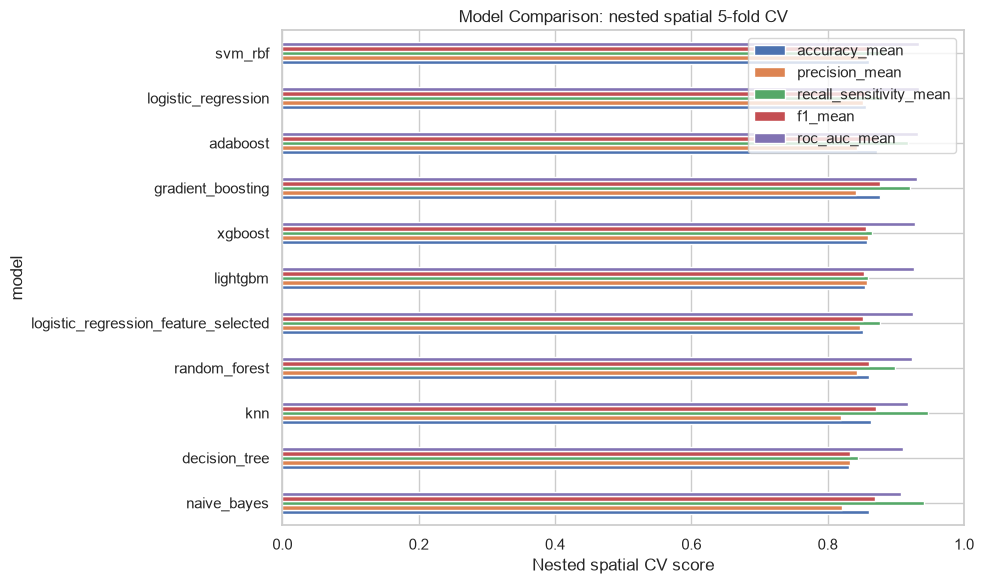

Best model by nested-CV ROC-AUC: svm_rbf


,mean_auc_diff_vs_best,std_of_diff,folds_best_wins
model,,,
logistic_regression,-0.001012,0.010833,2
adaboost,-0.002570,0.016040,3
gradient_boosting,-0.003933,0.024217,3
xgboost,-0.006542,0.026558,2
lightgbm,-0.007881,0.025141,3
logistic_regression_feature_selected,-0.009569,0.025813,3
random_forest,-0.010568,0.022397,3
knn,-0.015949,0.017251,5
decision_tree,-0.024094,0.026620,4


In [41]:
plot_cols = ['accuracy_mean', 'precision_mean', 'recall_sensitivity_mean', 'f1_mean', 'roc_auc_mean']
cv_plot = cv_results.set_index('model')[plot_cols].sort_values('roc_auc_mean')
cv_plot.plot(kind='barh', figsize=(10, 6))
plt.xlabel('Nested spatial CV score')
plt.title('Model Comparison: nested spatial 5-fold CV')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

# Paired comparison: fold-by-fold ROC-AUC difference against the best model (same folds for every model).
best_name = cv_results.iloc[0]['model']
auc_wide = fold_df.pivot(index='fold', columns='model', values='roc_auc')
paired = pd.DataFrame({
    'mean_auc_diff_vs_best': auc_wide.sub(auc_wide[best_name], axis=0).mean(),
    'std_of_diff': auc_wide.sub(auc_wide[best_name], axis=0).std(),
    'folds_best_wins': auc_wide.apply(lambda c: int((auc_wide[best_name] > c).sum())),
}).drop(index=best_name)
print('Best model by nested-CV ROC-AUC:', best_name)
paired.sort_values('mean_auc_diff_vs_best', ascending=False)

### Baseline sanity check

Any tuned model should clearly beat (1) a dummy classifier that ignores the features and (2) a plain, untuned Logistic Regression on the same blocked folds.

In [42]:
baseline_specs = {
    'dummy_prior': DummyClassifier(strategy='prior'),
    'untuned_logistic_regression': Pipeline([('preprocess', make_preprocessor('linear')),
                                              ('model', LogisticRegression(max_iter=5000, class_weight='balanced'))]),
}
base_rows = []
for bname, est in baseline_specs.items():
    for fold, (tr, va) in enumerate(outer_splits):
        e = clone(est).fit(X_train.iloc[tr], y_train.iloc[tr])
        base_rows.append({'model': bname, **evaluate_predictions(y_train.iloc[va], predict_proba_positive(e, X_train.iloc[va]), 0.5)})
baseline_df = pd.DataFrame(base_rows).groupby('model')[['accuracy', 'f1', 'roc_auc', 'pr_auc']].mean()
pd.concat([baseline_df, cv_results.set_index('model')[['accuracy_mean', 'f1_mean', 'roc_auc_mean', 'pr_auc_mean']]
           .rename(columns=lambda c: c.replace('_mean', ''))]).sort_values('roc_auc')

,accuracy,f1,roc_auc,pr_auc
model,,,,
dummy_prior,0.348682,0.348054,0.500000,0.542802
naive_bayes,0.860860,0.868982,0.907762,0.889862
decision_tree,0.831775,0.832472,0.910341,0.884307
knn,0.863369,0.871617,0.918486,0.889140
random_forest,0.860296,0.861306,0.923867,0.899248
logistic_regression_feature_selected,0.852396,0.852427,0.924866,0.912284
lightgbm,0.854062,0.852918,0.926554,0.901459
xgboost,0.858350,0.856499,0.927893,0.905512
gradient_boosting,0.876419,0.876475,0.930502,0.905176


### Decision thresholds from out-of-fold predictions

Each model's threshold maximizes Youden's J on its spatial out-of-fold training predictions. This threshold describes the sampled classes and does not depend on the sampled class ratio. It is evaluated once on the spatial test set.

In [43]:
oof_threshold = {n: youden_threshold(y_train, p) for n, p in oof_proba.items()}
pd.Series(oof_threshold, name='oof_youden_threshold')

logistic_regression                     0.382276
logistic_regression_feature_selected    0.305058
decision_tree                           0.219151
random_forest                           0.397457
svm_rbf                                 0.301747
gradient_boosting                       0.465698
knn                                     0.525159
naive_bayes                             0.086821
adaboost                                0.489808
xgboost                                 0.269272
lightgbm                                0.222836
Name: oof_youden_threshold, dtype: float64

## 8. Final Fit and Single Hold-out Evaluation

Each model is tuned once more on the whole training set (block-grouped inner CV), then evaluated exactly once on the held-out spatial blocks, both at 0.5 and at its OOF-derived threshold. Bootstrap confidence intervals show whether differences between models are meaningful.

In [44]:
# This cell depends on the nested-CV OOF probabilities from Section 7. If you ran cells out of order,
# compute the OOF thresholds here when possible, otherwise show a clear instruction.
if 'oof_threshold' not in globals():
    if 'oof_proba' not in globals():
        raise RuntimeError('Run Section 7 nested spatial cross-validation first to create oof_proba.')
    oof_threshold = {n: youden_threshold(y_train, p) for n, p in oof_proba.items()}

fitted_models, best_params, test_proba = {}, {}, {}
test_rows = []
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(300)]
y_test_arr = y_test.to_numpy()

for name, (pipe, dist) in model_specs.items():
    print(f'Fitting {name}...')
    search = search_with_buffer(clone(pipe), dist, X_train, y_train, g_train)
    fitted_models[name] = search.best_estimator_
    best_params[name] = {k: (v.item() if hasattr(v, 'item') else v) for k, v in search.best_params_.items()}
    proba = predict_proba_positive(search.best_estimator_, X_test)
    test_proba[name] = proba
    aucs = [roc_auc_score(y_test_arr[i], proba[i]) for i in boot_idx if len(np.unique(y_test_arr[i])) == 2]
    row = {'model': name, 'threshold': oof_threshold[name]}
    row.update(evaluate_predictions(y_test, proba, threshold=oof_threshold[name]))
    row['roc_auc_ci_low'], row['roc_auc_ci_high'] = np.percentile(aucs, [2.5, 97.5])
    row['f1_at_0.5'] = f1_score(y_test, (proba >= 0.5).astype(int))
    test_rows.append(row)

test_results = pd.DataFrame(test_rows).sort_values('roc_auc', ascending=False).reset_index(drop=True)
test_results

Fitting logistic_regression...


Fitting logistic_regression_feature_selected...


Fitting decision_tree...


Fitting random_forest...


Fitting svm_rbf...


...

Fitting naive_bayes...


Fitting adaboost...


Fitting xgboost...


Fitting lightgbm...


,model,threshold,accuracy,precision,recall_sensitivity,specificity,f1,balanced_accuracy,roc_auc,pr_auc,brier,cohen_kappa,roc_auc_ci_low,roc_auc_ci_high,f1_at_0.5
0,svm_rbf,0.301747,0.806697,0.692308,0.985752,0.673090,0.813373,0.829421,0.939736,0.904290,0.114157,0.625210,0.931837,0.947618,0.835199
1,logistic_regression_feature_selected,0.305058,0.782725,0.665072,0.990205,0.627907,0.795707,0.809056,0.923512,0.876603,0.129645,0.582003,0.914064,0.933080,0.820182
2,random_forest,0.397457,0.785769,0.667464,0.993767,0.630565,0.798569,0.812166,0.922971,0.888456,0.127197,0.587859,0.914331,0.933268,0.809382
3,logistic_regression,0.382276,0.790335,0.675245,0.981300,0.647841,0.800000,0.814570,0.921209,0.869073,0.131335,0.594920,0.911741,0.931085,0.819523
4,gradient_boosting,0.465698,0.820776,0.732194,0.915405,0.750166,0.813613,0.832786,0.916894,0.872204,0.124755,0.645086,0.907283,0.927291,0.810724
5,adaboost,0.489808,0.807458,0.699418,0.963491,0.691030,0.810487,0.827260,0.915590,0.852481,0.134762,0.624592,0.905111,0.926084,0.811157
6,xgboost,0.269272,0.790715,0.685677,0.942119,0.677741,0.793698,0.809930,0.910938,0.869884,0.129049,0.591772,0.901738,0.921787,0.802932
7,lightgbm,0.222836,0.805556,0.718884,0.894924,0.738870,0.797303,0.816897,0.908755,0.867950,0.158745,0.614692,0.898767,0.920223,0.800495
8,knn,0.525159,0.785388,0.669702,0.982191,0.638538,0.796390,0.810364,0.908581,0.838712,0.153066,0.586026,0.898343,0.917907,0.791114
9,decision_tree,0.219151,0.764079,0.646476,0.988424,0.596678,0.781690,0.792551,0.899636,0.819776,0.142302,0.548296,0.888942,0.911277,0.787690


In [45]:
print('Selected by nested CV (not by the test set):', best_name)
pd.DataFrame(best_params).T

Selected by nested CV (not by the test set): svm_rbf


,model__C,select__k,model__max_depth,model__min_samples_leaf,model__max_features,model__gamma,model__l2_regularization,model__learning_rate,model__max_iter,model__n_neighbors,...,model__weights,model__var_smoothing,model__estimator__max_depth,model__n_estimators,model__colsample_bytree,model__min_child_weight,model__reg_lambda,model__subsample,model__min_child_samples,model__num_leaves
logistic_regression,0.017074,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
logistic_regression_feature_selected,0.314891,36.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_tree,NaN,NaN,10.0,57.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
random_forest,NaN,NaN,16,5,sqrt,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
svm_rbf,0.143472,NaN,NaN,NaN,NaN,0.053995,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gradient_boosting,NaN,NaN,5.0,21.0,NaN,NaN,0.401378,0.022774,393.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
knn,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43,...,uniform,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
naive_bayes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.040338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
adaboost,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.034975,NaN,NaN,...,NaN,NaN,4.0,180.0,NaN,NaN,NaN,NaN,NaN,NaN
xgboost,NaN,NaN,5.0,NaN,NaN,NaN,NaN,0.022774,NaN,NaN,...,NaN,NaN,NaN,485.0,0.85,6.0,0.035114,0.7,NaN,NaN


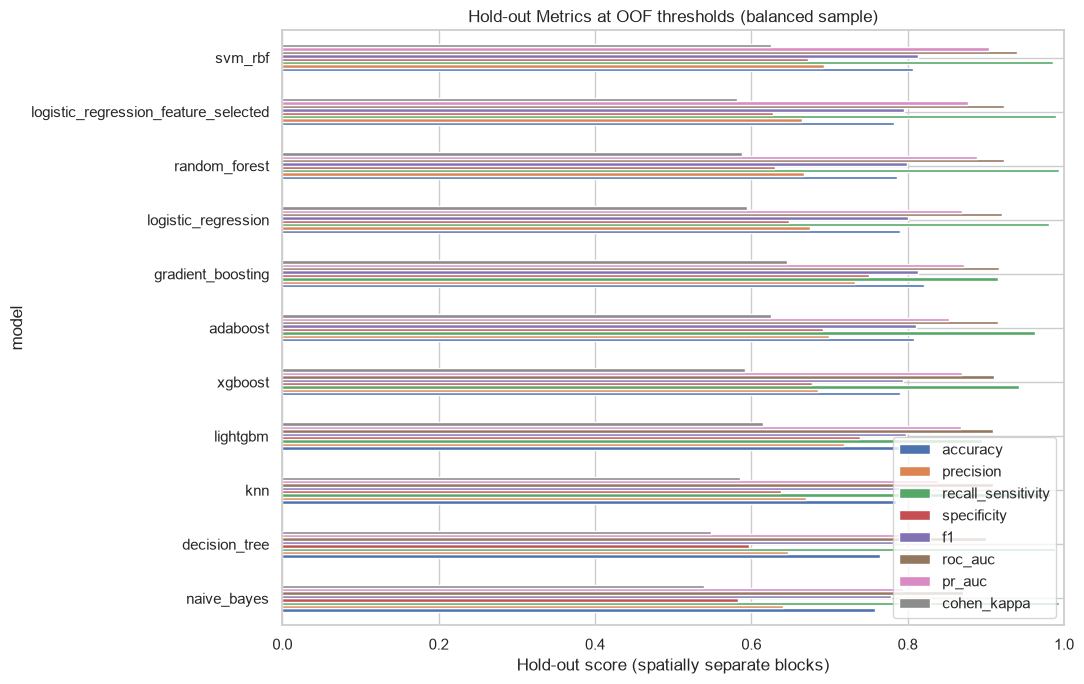

In [46]:
metric_cols = ['accuracy', 'precision', 'recall_sensitivity', 'specificity', 'f1', 'roc_auc', 'pr_auc', 'cohen_kappa']
plot_df = test_results.set_index('model')[metric_cols].sort_values('roc_auc')
plot_df.plot(kind='barh', figsize=(11, 7))
plt.xlabel('Hold-out score (spatially separate blocks)')
plt.title(f'Hold-out Metrics at OOF thresholds (balanced sample)')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

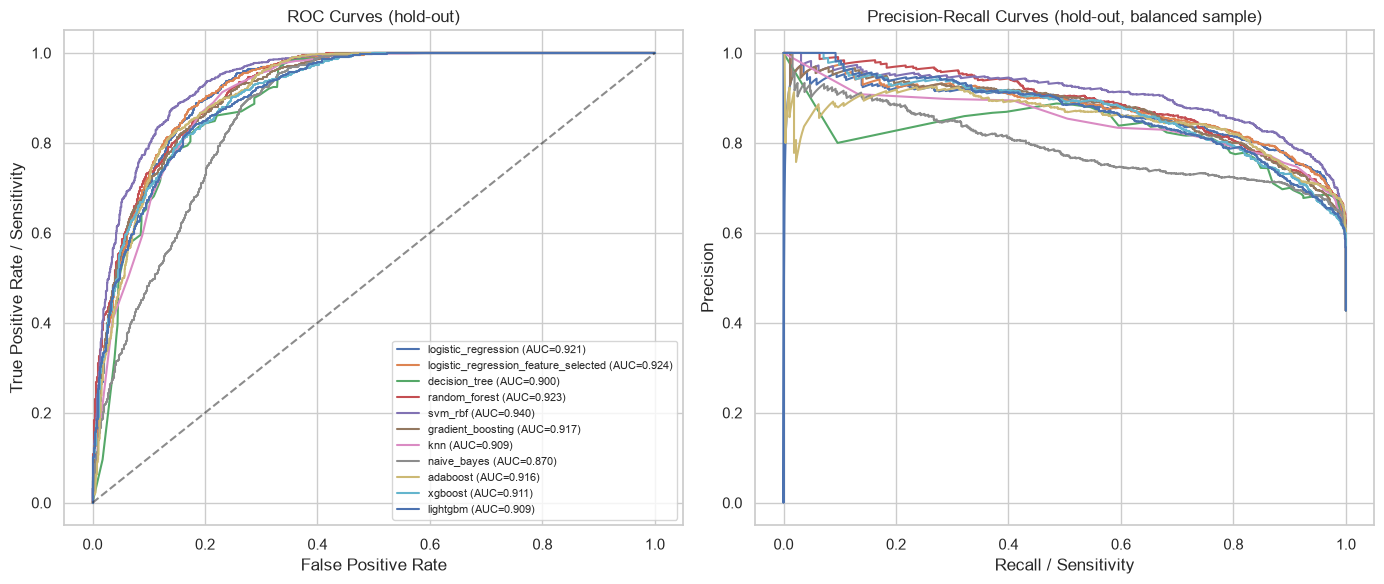

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name in fitted_models:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, test_proba[name]):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, test_proba[name])
    axes[1].plot(rec, prec, label=f'{name} (PR-AUC={average_precision_score(y_test, test_proba[name]):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate / Sensitivity', title='ROC Curves (hold-out)')
axes[1].set(xlabel='Recall / Sensitivity', ylabel='Precision', title='Precision-Recall Curves (hold-out, balanced sample)')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Threshold Analysis and Confusion Matrix

The threshold curve below is drawn from **out-of-fold training predictions**, not from the test set. The confusion matrix on the test set uses the OOF-derived threshold.

svm_rbf: OOF Youden threshold = 0.302


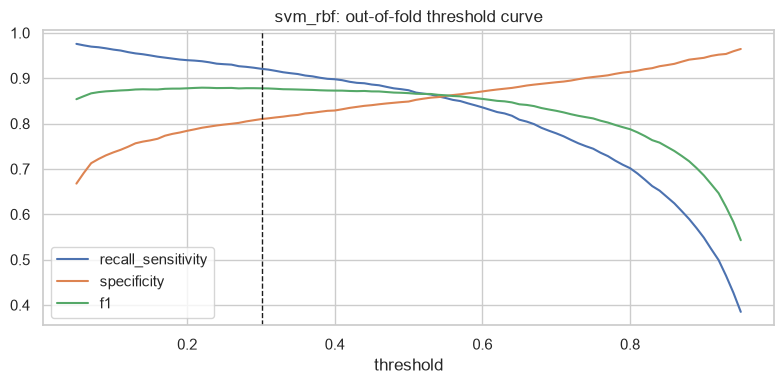

In [48]:
if 'oof_threshold' not in globals():
    if 'oof_proba' not in globals():
        raise RuntimeError('Run Section 7 nested spatial cross-validation first to create oof_proba.')
    oof_threshold = {n: youden_threshold(y_train, p) for n, p in oof_proba.items()}

best_oof = oof_proba[best_name]
thr_rows = []
for t in np.linspace(0.05, 0.95, 91):
    r = evaluate_predictions(y_train, best_oof, threshold=t)
    thr_rows.append({'threshold': t, **r})
threshold_df = pd.DataFrame(thr_rows)
best_threshold = oof_threshold[best_name]
print(f'{best_name}: OOF Youden threshold = {best_threshold:.3f}')

threshold_df.plot(x='threshold', y=['recall_sensitivity', 'specificity', 'f1'], figsize=(8, 4))
plt.axvline(best_threshold, color='k', linestyle='--', linewidth=1)
plt.title(f'{best_name}: out-of-fold threshold curve')
plt.tight_layout()
plt.show()

               precision    recall  f1-score   support

non_landslide       0.98      0.67      0.80      1505
    landslide       0.69      0.99      0.81      1123

     accuracy                           0.81      2628
    macro avg       0.84      0.83      0.81      2628
 weighted avg       0.86      0.81      0.81      2628



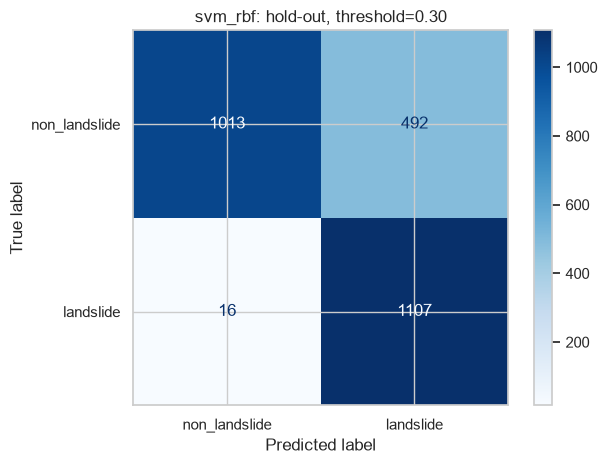

In [49]:
best_model = fitted_models[best_name]
best_proba = test_proba[best_name]
best_pred = (best_proba >= best_threshold).astype(int)
print(classification_report(y_test, best_pred, target_names=['non_landslide', 'landslide']))
cm = confusion_matrix(y_test, best_pred)
ConfusionMatrixDisplay(cm, display_labels=['non_landslide', 'landslide']).plot(cmap='Blues')
plt.title(f'{best_name}: hold-out, threshold={best_threshold:.2f}')
plt.tight_layout()
plt.show()

## 10. Sample-Distribution Calibration

Isotonic calibration is fit to the selected model's spatial out-of-fold training scores and checked on the independent spatial test blocks. It targets the sampled 1:1 class distribution. Mapping outputs should be described as relative susceptibility scores, not landslide event probabilities.

,raw,isotonic_calibrated
brier,0.114157,0.129297
roc_auc,0.939736,0.938783


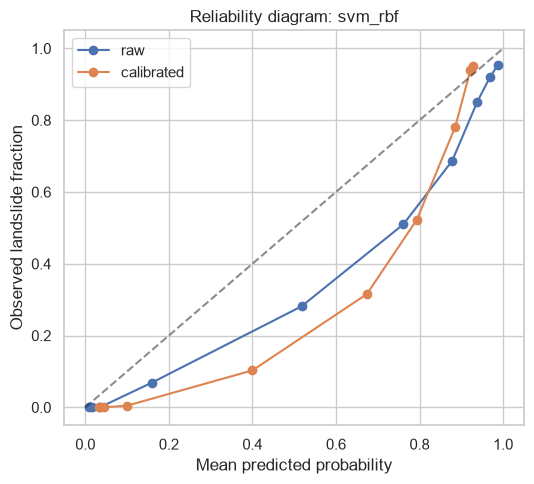

In [50]:
calibrator = IsotonicRegression(out_of_bounds='clip').fit(best_oof, y_train)
cal_proba = calibrator.predict(best_proba)
cal_threshold = float(calibrator.predict([best_threshold])[0])

calib_cmp = pd.DataFrame({
    'raw': {'brier': brier_score_loss(y_test, best_proba), 'roc_auc': roc_auc_score(y_test, best_proba)},
    'isotonic_calibrated': {'brier': brier_score_loss(y_test, cal_proba), 'roc_auc': roc_auc_score(y_test, cal_proba)},
})
display(calib_cmp)

plt.figure(figsize=(5.5, 5))
for label, p in [('raw', best_proba), ('calibrated', cal_proba)]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    plt.plot(mean_pred, frac_pos, marker='o', label=label)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed landslide fraction')
plt.title(f'Reliability diagram: {best_name}')
plt.legend()
plt.tight_layout()
plt.show()

## 11. Temporal Robustness Check

Early-date versus late-date evaluation is a supplementary sensitivity check. Each pseudo-absence takes its paired landslide's date, and the date split does not enforce spatial independence. Model settings and threshold were selected using the spatial training set, so this result is descriptive rather than an independent prospective test.

In [51]:
dates = pd.to_datetime(df['event_date'])
cutoff = dates.quantile(0.8)
early, late = (dates <= cutoff).to_numpy(), (dates > cutoff).to_numpy()
temporal_model = clone(fitted_models[best_name]).fit(X[early], y[early])
t_proba = predict_proba_positive(temporal_model, X[late])
temporal_metrics = evaluate_predictions(y[late], t_proba, threshold=best_threshold)
print(f'Train: events up to {cutoff.date()} (n={early.sum()}), test: later events (n={late.sum()})')
print('Temporal hold-out ROC-AUC:', round(temporal_metrics['roc_auc'], 3),
      '| PR-AUC:', round(temporal_metrics['pr_auc'], 3),
      '| sensitivity:', round(temporal_metrics['recall_sensitivity'], 3),
      '| specificity:', round(temporal_metrics['specificity'], 3))
print('Spatial hold-out ROC-AUC (for comparison):', round(roc_auc_score(y_test, best_proba), 3))

Train: events up to 2017-03-04 (n=11146), test: later events (n=1214)
Temporal hold-out ROC-AUC: 0.918 | PR-AUC: 0.896 | sensitivity: 0.862 | specificity: 0.839
Spatial hold-out ROC-AUC (for comparison): 0.94


## 12. Feature Importance and Logistic Regression Coefficients

In [52]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring='roc_auc', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)
importance = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std,
}).sort_values('importance_mean', ascending=False)
importance.head(30)

,feature,importance_mean,importance_std
18,ndvi,0.060446,0.002498
0,elevation,0.043677,0.003058
7,ls_factor,0.011934,0.002192
16,dist_to_river,0.011025,0.001199
6,tpi,0.009614,0.001707
4,curvature_profile,0.006206,0.001377
2,aspect,0.004734,0.000786
13,soil_sand_pct,0.003400,0.000411
5,tri,0.002685,0.001430
11,soil_texture,0.002565,0.000293


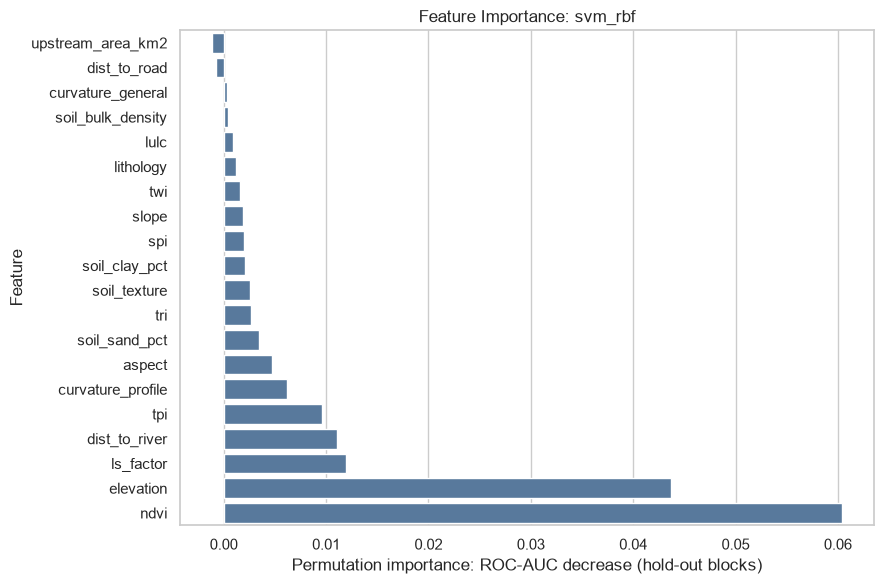

In [53]:
top = importance.head(25).sort_values('importance_mean')
plt.figure(figsize=(9, max(5, len(top) * 0.3)))
sns.barplot(data=top, x='importance_mean', y='feature', color='#4C78A8')
plt.xlabel('Permutation importance: ROC-AUC decrease (hold-out blocks)')
plt.ylabel('Feature')
plt.title(f'Feature Importance: {best_name}')
plt.tight_layout()
plt.show()

In [54]:
# Logistic Regression coefficients (on transformed, standardised features).
if 'logistic_regression' in fitted_models:
    lr_pipe = fitted_models['logistic_regression']
    feature_names = lr_pipe.named_steps['preprocess'].named_steps['columns'].get_feature_names_out()
    coefs = lr_pipe.named_steps['model'].coef_[0]
    coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefs})
    coef_df['abs_coefficient'] = coef_df['coefficient'].abs()
    display(coef_df.sort_values('abs_coefficient', ascending=False).head(30))

,feature,coefficient,abs_coefficient
0,num__elevation,1.282545,1.282545
15,num__ndvi,-0.752105,0.752105
6,num__ls_factor,0.736236,0.736236
32,cat__lithology_Mixed sedimentary rocks,0.584215,0.584215
5,num__tpi,-0.395492,0.395492
4,num__tri,0.373538,0.373538
29,cat__lithology_Acid plutonic rocks,-0.363438,0.363438
57,cat__soil_texture_6.0,0.359838,0.359838
3,num__curvature_profile,0.319966,0.319966
58,cat__soil_texture_7.0,-0.310152,0.310152


## 13. Save Final Model and Sample Scores

The deployment model is refit on all labeled samples. `heldout_score` contains outer-CV scores for retained training rows and hold-out scores for test rows; rows embargoed from the final training split have no held-out score. `final_model_insample_score` is explicitly in-sample. The five bins are descriptive relative-score classes on this **sample**, not calibrated population-risk categories or an area-wide susceptibility map.

In [55]:
final_model = clone(fitted_models[best_name]).fit(X, y)
scores = df[['id', 'event_date', 'longitude', 'latitude', 'landslide']].copy()
scores['split'] = 'embargoed'
scores.loc[scores.index[train_idx], 'split'] = 'train'
scores.loc[scores.index[test_idx], 'split'] = 'test'
scores['heldout_score'] = np.nan
scores.iloc[train_idx, scores.columns.get_loc('heldout_score')] = best_oof
scores.iloc[test_idx, scores.columns.get_loc('heldout_score')] = best_proba
scores['final_model_insample_score'] = predict_proba_positive(final_model, X)
calibrated_heldout = np.full(len(scores), np.nan)
has_heldout = scores['heldout_score'].notna().to_numpy()
calibrated_heldout[has_heldout] = calibrator.predict(scores.loc[has_heldout, 'heldout_score'].to_numpy())
scores['relative_score_class'] = pd.cut(
    calibrated_heldout,
    bins=[-0.001, 0.2, 0.4, 0.6, 0.8, 1.001],
    labels=['very_low', 'low', 'moderate', 'high', 'very_high'],
)
score_path = ARTIFACT_DIR / 'landslide_sample_susceptibility_scores.csv'
scores.to_csv(score_path, index=False)
scores.head()

,id,event_date,longitude,latitude,landslide,split,heldout_score,final_model_insample_score,relative_score_class
0,LS_17863,2019-02-25,98.944362,8.279069,1,train,0.928006,0.971859,very_high
1,LS_17864,2019-02-11,98.736813,8.640706,1,test,0.963125,0.930988,very_high
2,LS_17865,2019-04-11,98.736831,8.640661,1,test,0.968911,0.919826,very_high
3,LS_17866,2019-02-11,98.738023,8.638663,1,test,0.976874,0.983207,very_high
4,LS_17867,2019-04-11,98.737832,8.638744,1,test,0.976458,0.981387,very_high


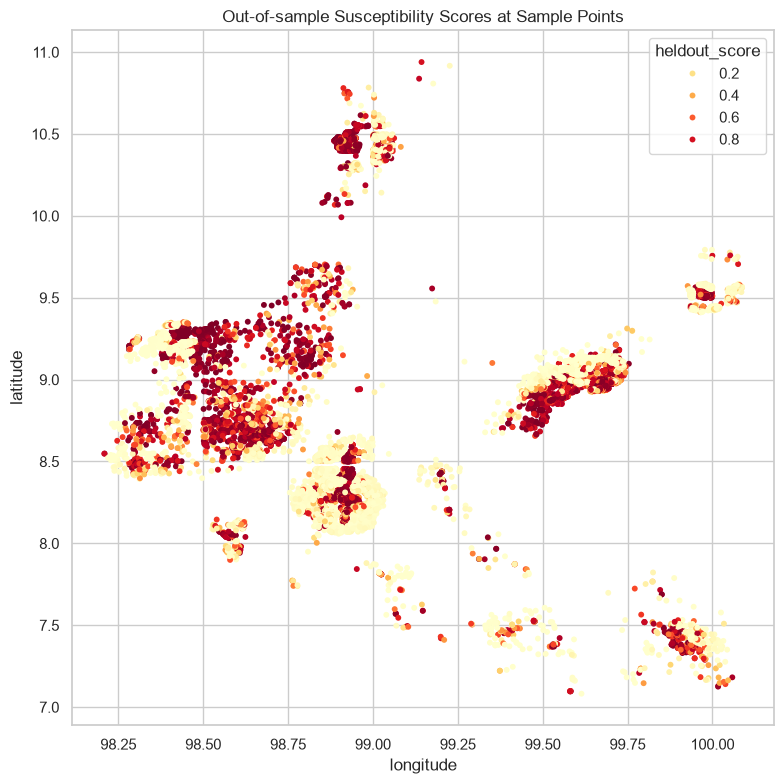

In [56]:
plt.figure(figsize=(8, 8))
sns.scatterplot(
    data=scores, x='longitude', y='latitude', hue='heldout_score',
    palette='YlOrRd', s=18, linewidth=0,
)
plt.title('Out-of-sample Susceptibility Scores at Sample Points')
plt.tight_layout()
plt.show()

In [57]:
model_path = ARTIFACT_DIR / f'{best_name}_landslide_susceptibility_pipeline.joblib'
calibrator_path = ARTIFACT_DIR / f'{best_name}_isotonic_calibrator.joblib'
joblib.dump(final_model, model_path)
joblib.dump(calibrator, calibrator_path)

metadata = {
    'best_model': best_name,
    'selection': 'nested spatial CV (ROC-AUC)',
    'best_params': best_params,
    'threshold_raw_probability': float(best_threshold),
    'threshold_calibrated_probability': cal_threshold,
    'sample_prevalence': float(y.mean()),
    'score_interpretation': 'relative susceptibility under synthetic pseudo-absence sampling',
    'spatial_buffer_km': BUFFER_KM,
    'holdout_fold': int(holdout_fold),
    'holdout_selection': 'fixed-seed grouped fold closest to overall class share and 20 percent test size; labels only',
    'training_class_counts': {str(k): int(v) for k, v in y_train.value_counts().items()},
    'test_class_counts': {str(k): int(v) for k, v in y_test.value_counts().items()},
    'embargoed_training_rows': int(len(raw_train_idx) - len(train_idx)),
    'spatial_block_deg': BLOCK_DEG,
    'feature_columns': feature_cols,
    'numeric_features': num_features,
    'categorical_features': cat_features,
    'excluded_columns': ['id', 'event_date'] + COORD_COLS,
    'cv_results': cv_results.to_dict(orient='records'),
    'test_results': test_results.to_dict(orient='records'),
    'temporal_holdout_descriptive': {k: float(v) for k, v in temporal_metrics.items()},
}
metadata_path = ARTIFACT_DIR / 'model_metadata.json'
metadata_path.write_text(json.dumps(metadata, indent=2, default=str))
print('Saved model:', model_path)
print('Saved calibrator:', calibrator_path)
print('Saved metadata:', metadata_path)
print('Saved sample scores:', score_path)

Saved model: models/susceptibility/svm_rbf_landslide_susceptibility_pipeline.joblib
Saved calibrator: models/susceptibility/svm_rbf_isotonic_calibrator.joblib
Saved metadata: models/susceptibility/model_metadata.json
Saved sample scores: models/susceptibility/landslide_sample_susceptibility_scores.csv


## 13b. Saved-Model Reload Check

Reloading the saved model and scoring five rows checks serialization and feature order. These rows were part of the final full-data refit, so this cell does **not** estimate out-of-sample performance. Use the spatial hold-out and nested CV results above for that purpose.

In [58]:
import sys
sys.path.insert(0, str(Path.cwd() if (Path.cwd() / 'susc_utils.py').exists() else Path.cwd() / 'notebooks'))  # so joblib can import susc_utils

reloaded_model = joblib.load(model_path)
reloaded_calibrator = joblib.load(calibrator_path)
meta = json.loads(metadata_path.read_text())

new_rows = X_test.iloc[:5][meta['feature_columns']]          # rows included in final refit; reload test only
raw_p = reloaded_model.predict_proba(new_rows)[:, 1]
cal_p = reloaded_calibrator.predict(raw_p)
inference = pd.DataFrame({
    'raw_sample_score': raw_p.round(3),
    'calibrated_sample_score': cal_p.round(3),
    'predicted_landslide': (raw_p >= meta['threshold_raw_probability']).astype(int),
    'actual_label': y_test.iloc[:5].to_numpy(),
}, index=new_rows.index)
assert np.allclose(raw_p, final_model.predict_proba(new_rows)[:, 1]), 'reloaded model differs from in-memory model'
inference

,raw_sample_score,calibrated_sample_score,predicted_landslide,actual_label
1,0.931,0.904,1,1
2,0.920,0.904,1,1
3,0.983,0.922,1,1
4,0.981,0.922,1,1
5,0.973,0.922,1,1


## 14. Applying the Model to a Susceptibility Grid

The grid must contain all `feature_columns` with the same units and category names. Longitude and latitude are retained only for display. Include `notebooks/susc_utils.py` on the Python path when loading the model.

```python
grid = pd.read_csv('your_factor_grid.csv')
model = joblib.load('models/susceptibility/<best_model>_landslide_susceptibility_pipeline.joblib')
calibrator = joblib.load('models/susceptibility/<best_model>_isotonic_calibrator.joblib')
raw = model.predict_proba(grid[feature_columns])[:, 1]
grid['relative_susceptibility_score'] = calibrator.predict(raw)
grid.to_csv('susceptibility_grid_scores.csv', index=False)
```

These scores are calibrated to the balanced point sample and its synthetic pseudo-absences. They are **not** the probability that a map cell will fail. A probability map needs a defined prediction period, representative non-event sampling, independent validation, and an area-wide event prevalence or prospective calibration data. Check grid feature ranges and missingness against the training sample before mapping.